!pip install catboost

In [ ]:
import sklearn
import tensorflow
import lightgbm
print(sklearn.__version__)
print(tensorflow.__version__)
print(lightgbm.__version__)

1.6.1
2.18.0
4.5.0


In [ ]:
"Gordon, R. (2022). Prototype for Amex [Notebook]. Kaggle. https://www.kaggle.com/code/robgordon2077/prototype-for-amex"
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
import lightgbm as lgb
import tensorflow as tf
import xgboost as xgb
from pyspark.sql import SparkSession
from pyspark.sql.functions import mean,col, when
pd.set_option("display.max_columns",200)
pd.set_option("display.max_rows",None)

In [ ]:
spark = SparkSession.builder.appName("MySparkApp").master("local[*]").getOrCreate()
df = spark.read.csv("/content/drive/MyDrive/Kaggle competition/Amex-Default prediction/amex-default-prediction/train_data.csv", header=True, inferSchema=True)

In [ ]:
df.count()

5531451

In [ ]:
""""Tiwari, K. (2022). Base level data engineering and file load [Notebook]. Kaggle. https://www.kaggle.com/code/kshitiztiwari/base-level-data-engineering-and-file-load"""
sample_data=[]
sum=0
chunks=pd.read_csv('/content/drive/MyDrive/Kaggle competition/Amex-Default prediction/amex-default-prediction/train_data.csv',chunksize=1000000)
for chunk in chunks:
  sum+=chunk.shape[0]
  sample_data.append(chunk.sample(frac=.1))
df=
chunks=''
print(f"Records used for creating mchine Learning model: {df.shape[0]}")
print(f"Total number of records: {sum}")

In [ ]:
df.to_csv('my_dataframe.csv', index=False)


In [ ]:
df=pd.read_csv('/content/drive/MyDrive/Courses/Advance business analytics/Assignment 4/my_dataframe.csv')

**Data Cleaning**

In [ ]:
cols=['B_30', 'B_38', 'D_114', 'D_116', 'D_117', 'D_120', 'D_126', 'D_63', 'D_64', 'D_66', 'D_68']
for col in cols:
  if col in df.columns:
    if df[col].dtype != 'category':
        df[col] = df[col].astype('category')
    print(f"Unique values in column {col}: {df[col].unique()}")

Unique values in column B_30: [0.0, 1.0, 2.0, NaN]
Categories (3, float64): [0.0, 1.0, 2.0]
Unique values in column B_38: [3.0, 1.0, 2.0, 6.0, 4.0, 5.0, 7.0, NaN]
Categories (7, float64): [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0]
Unique values in column D_114: [0.0, 1.0, NaN]
Categories (2, float64): [0.0, 1.0]
Unique values in column D_116: [0.0, NaN, 1.0]
Categories (2, float64): [0.0, 1.0]
Unique values in column D_117: [6.0, 5.0, 3.0, 4.0, 2.0, NaN, -1.0, 1.0]
Categories (7, float64): [-1.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0]
Unique values in column D_120: [0.0, 1.0, NaN]
Categories (2, float64): [0.0, 1.0]
Unique values in column D_126: [1.0, 0.0, NaN, -1.0]
Categories (3, float64): [-1.0, 0.0, 1.0]
Unique values in column D_63: ['CO', 'CL', 'CR', 'XL', 'XM', 'XZ']
Categories (6, object): ['CL', 'CO', 'CR', 'XL', 'XM', 'XZ']
Unique values in column D_64: ['R', 'O', 'U', NaN, '-1']
Categories (4, object): ['-1', 'O', 'R', 'U']
Unique values in column D_66: [NaN, 1.0, 0.0]
Categories (2, float

In [ ]:
# Sort by customer_ID and date to get correct order
df = df.sort_values(['customer_ID', 'S_2'])

# Pick the last row for each customer (i.e., their latest transaction/month)
grouped_df = df.groupby('customer_ID').tail(1).reset_index(drop=True)

In [ ]:
grouped_df.shape
df=grouped_df

In [ ]:
df.isnull().sum()

,0
customer_ID,0
S_2,0
P_2,2619
D_39,0
B_1,0
B_2,102
R_1,0
S_3,59581
D_41,102
B_3,102


In [ ]:
print(f"Number of columns in the dataset:{df.shape[1]}")

new_df= df.loc[:, df.isnull().mean() < 0.5]
removed_columns = df.columns.difference(new_df.columns).to_list()
df=new_df
print(removed_columns)
print(f"Number of columns remaining after dropping columns with over 50% missing values: {df.shape[1]}")

Number of columns in the dataset:190
['B_17', 'B_29', 'B_39', 'B_42', 'D_105', 'D_106', 'D_108', 'D_110', 'D_111', 'D_132', 'D_134', 'D_135', 'D_136', 'D_137', 'D_138', 'D_142', 'D_42', 'D_49', 'D_50', 'D_53', 'D_56', 'D_66', 'D_73', 'D_76', 'D_82', 'D_87', 'D_88', 'R_26', 'R_9', 'S_9']
Number of columns remaining after dropping columns with over 50% missing values: 160


In [ ]:
df.head()

,customer_ID,S_2,P_2,D_39,B_1,B_2,R_1,S_3,D_41,B_3,D_43,D_44,B_4,D_45,B_5,R_2,D_46,D_47,D_48,B_6,B_7,B_8,D_51,B_9,R_3,D_52,P_3,B_10,S_5,B_11,S_6,D_54,R_4,S_7,B_12,S_8,D_55,B_13,R_5,D_58,B_14,D_59,D_60,D_61,B_15,S_11,D_62,D_63,D_64,D_65,B_16,B_18,B_19,B_20,D_68,S_12,R_6,S_13,B_21,D_69,B_22,D_70,D_71,D_72,S_15,B_23,P_4,D_74,D_75,B_24,R_7,D_77,B_25,B_26,D_78,D_79,R_8,S_16,D_80,R_10,R_11,B_27,D_81,S_17,R_12,B_28,R_13,D_83,R_14,R_15,D_84,R_16,B_30,S_18,D_86,R_17,R_18,B_31,S_19,R_19,B_32,S_20,R_20,R_21,B_33,D_89,R_22,R_23,D_91,D_92,D_93,D_94,R_24,R_25,D_96,S_22,S_23,S_24,S_25,S_26,D_102,D_103,D_104,D_107,B_36,B_37,R_27,B_38,D_109,D_112,B_40,S_27,D_113,D_114,D_115,D_116,D_117,D_118,D_119,D_120,D_121,D_122,D_123,D_124,D_125,D_126,D_127,D_128,D_129,B_41,D_130,D_131,D_133,R_28,D_139,D_140,D_141,D_143,D_144,D_145
0,0000099d6bd597052cdcda90ffabf56573fe9d7c79be5f...,2017-06-13,0.960384,0.002455,0.013683,1.002700,0.001373,0.117169,0.000685,0.005531,NaN,0.006406,0.055630,0.723997,0.166782,0.009918,0.323271,0.530929,0.135586,0.083720,0.049253,0.001418,1.339909,0.006782,0.003515,0.208214,0.741813,0.134437,0.030063,0.009667,0.000783,1.007456,0.008706,0.102838,0.129017,0.704016,0.275055,0.120740,0.004980,0.138100,0.012498,0.065926,0.273553,0.204300,0.022732,0.405175,0.094854,CR,O,0.005899,0.005896,0.654358,0.005897,0.005207,6.0,0.508670,0.008183,0.515282,0.008716,0.005271,0.004554,0.002052,0.150209,0.005364,0.206394,0.031705,0.009559,0.077490,0.071547,0.005595,0.006363,NaN,0.000646,0.009193,0.008568,0.003895,0.005153,0.004876,0.005665,0.001888,0.004961,0.000034,0.004652,0.006969,1.004728,0.060634,0.009982,0.008817,0.008690,0.007364,0.005924,0.008802,0.0,0.002520,0.003324,0.009455,0.008348,1,0.007053,0.003909,0.002478,0.006614,0.009977,0.007686,1.002775,0.007791,0.000458,0.007320,1.503701,1.007036,0.000664,0.003200,0.008507,0.004858,0.000063,0.913205,0.140058,0.926341,0.975499,0.007571,0.808214,1.001517,1.004514,0.672620,0.002729,0.011720,1.005338,2.0,0.009703,1.002538,0.153939,0.844667,0.000053,1.0,0.240910,0.0,4.0,0.239400,0.240727,0.0,0.711546,0.436903,0.005135,0.687779,0.004649,1.0,1.001671,1.003460,1.007573,0.007703,0.007108,0.008261,0.007206,0.002409,0.006117,0.004516,0.003200,0.008419,0.006527,0.009600
1,00000fd6641609c6ece5454664794f0340ad84dddce9a2...,2017-12-29,0.861109,0.302357,0.006711,0.819772,0.007966,0.139138,0.000728,0.005235,0.079258,0.002812,0.001098,0.267228,0.006571,0.000905,0.471737,0.399547,0.105999,0.225348,0.017709,0.003802,0.339235,0.006873,0.100048,0.241398,0.531948,0.296570,0.008128,0.000416,0.002475,1.003239,0.001278,0.095556,0.029998,0.330290,0.039435,0.068684,0.004056,0.000803,0.010855,0.237700,0.403688,0.019949,0.005928,0.449285,0.239895,CO,O,0.001572,0.090947,1.000319,0.001873,0.006513,6.0,0.192624,0.008571,0.001373,0.005025,0.006012,0.006626,0.007491,0.014687,0.005254,0.300994,0.002473,0.001176,0.007430,0.007739,0.005513,0.009534,0.218147,0.016012,0.001688,0.003427,0.006466,0.009750,0.008904,0.007229,0.007372,0.009307,0.006429,0.008378,0.004212,1.008367,0.008966,0.003675,0.002165,0.002812,0.003835,0.002214,0.001464,0.0,0.002989,0.000434,0.003204,0.000289,1,0.007946,0.001519,0.005115,0.000802,0.003773,0.004639,1.009193,0.002250,0.006015,0.009337,0.005723,0.008599,0.008896,0.007610,0.000912,0.000542,0.008214,0.890647,0.137226,0.887476,0.970308,0.003408,0.007856,0.009761,0.000430,0.009406,0.009352,0.005969,1.008917,2.0,0.008268,1.006045,0.015016,0.008753,0.004611,1.0,0.449402,0.0,-1.0,0.442696,0.438604,1.0,0.540915,0.286004,0.009921,0.145458,0.002831,1.0,0.002402,1.002310,0.001449,0.009520,0.002295,0.007907,0.005307,0.005935,0.008488,0.009377,0.000191,0.004603,0.003133,0.007844
2,000041bdba6ecadd89a52d11886e8eaaec9325906c9723...,2017-12-29,0.614427,0.007425,0.015824,0.962010,0.004479,0.369885,0.004799,0.009391,0.055777,0.002696,0.015474,0.079261,0.072228,0.007786,0.442432,0.404807,0.092988,0.176701,0.027479,1.006054,0.001530,0.028851,0.007758,0.195300,0.704214,0.192981,0.058831,0.010140,0.005843,1.007432,0.001348,0.3

In [ ]:
df_train_labels=pd.read_csv('/content/drive/MyDrive/Courses/Advance business analytics/Assignment 4/amex-default-prediction/train_labels.csv')

In [ ]:
df = pd.merge(df, df_train_labels, on='customer_ID', how='inner')

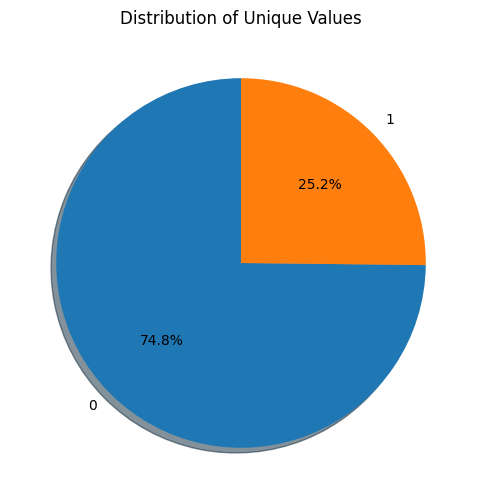

In [ ]:
value_counts = df['target'].value_counts()
plt.figure(figsize=(6, 6))
value_counts.plot.pie(autopct='%1.1f%%', startangle=90, shadow=True)
plt.title('Distribution of Unique Values')
plt.ylabel('')  # Hide y-label
plt.show()

In [ ]:
df.shape

(323413, 161)

In [ ]:
df.drop(['customer_ID','S_2'],axis=1,inplace=True)

Exploratory Data Analyis

In [ ]:
col_summary = {}

for col in df.columns:
    if df[col].dtype in ['object', 'category']:
        # Use mode (most frequent value)
        mode_val = df[col].mode(dropna=True)
        col_summary[col] = mode_val[0] if not mode_val.empty else None
    else:
        # Use mean (for numeric columns)
        col_summary[col] = df[col].mean(skipna=True)
df.fillna(value=col_summary, inplace=True)

In [ ]:
"""prefix_map = {
    'D_': 'Deliquency',
    'S_': 'Spend',
    'P_': 'Payment',
    'B_': 'Balance',
    'R_': 'Risk'
}

for prefix, new_col in prefix_map.items():
    cols = df.filter(regex=f'^{prefix}').select_dtypes(include='number')
    df[new_col] = cols.mean(axis=1)"""

"prefix_map = {\n    'D_': 'Deliquency',\n    'S_': 'Spend',\n    'P_': 'Payment',\n    'B_': 'Balance',\n    'R_': 'Risk'\n}\n\nfor prefix, new_col in prefix_map.items():\n    cols = df.filter(regex=f'^{prefix}').select_dtypes(include='number')\n    df[new_col] = cols.mean(axis=1)"

In [ ]:
df.head()

,P_2,D_39,B_1,B_2,R_1,S_3,D_41,B_3,D_43,D_44,B_4,D_45,B_5,R_2,D_46,D_47,D_48,B_6,B_7,B_8,D_51,B_9,R_3,D_52,P_3,B_10,S_5,B_11,S_6,D_54,R_4,S_7,B_12,S_8,D_55,B_13,R_5,D_58,B_14,D_59,D_60,D_61,B_15,S_11,D_62,D_63,D_64,D_65,B_16,B_18,B_19,B_20,D_68,S_12,R_6,S_13,B_21,D_69,B_22,D_70,D_71,D_72,S_15,B_23,P_4,D_74,D_75,B_24,R_7,D_77,B_25,B_26,D_78,D_79,R_8,S_16,D_80,R_10,R_11,B_27,D_81,S_17,R_12,B_28,R_13,D_83,R_14,R_15,D_84,R_16,B_30,S_18,D_86,R_17,R_18,B_31,S_19,R_19,B_32,S_20,R_20,R_21,B_33,D_89,R_22,R_23,D_91,D_92,D_93,D_94,R_24,R_25,D_96,S_22,S_23,S_24,S_25,S_26,D_102,D_103,D_104,D_107,B_36,B_37,R_27,B_38,D_109,D_112,B_40,S_27,D_113,D_114,D_115,D_116,D_117,D_118,D_119,D_120,D_121,D_122,D_123,D_124,D_125,D_126,D_127,D_128,D_129,B_41,D_130,D_131,D_133,R_28,D_139,D_140,D_141,D_143,D_144,D_145,target
0,0.960384,0.002455,0.013683,1.002700,0.001373,0.117169,0.000685,0.005531,0.156902,0.006406,0.055630,0.723997,0.166782,0.009918,0.323271,0.530929,0.135586,0.083720,0.049253,0.001418,1.339909,0.006782,0.003515,0.208214,0.741813,0.134437,0.030063,0.009667,0.000783,1.007456,0.008706,0.102838,0.129017,0.704016,0.275055,0.120740,0.004980,0.138100,0.012498,0.065926,0.273553,0.204300,0.022732,0.405175,0.094854,CR,O,0.005899,0.005896,0.654358,0.005897,0.005207,6.0,0.508670,0.008183,0.515282,0.008716,0.005271,0.004554,0.002052,0.150209,0.005364,0.206394,0.031705,0.009559,0.077490,0.071547,0.005595,0.006363,0.257571,0.000646,0.009193,0.008568,0.003895,0.005153,0.004876,0.005665,0.001888,0.004961,0.000034,0.004652,0.006969,1.004728,0.060634,0.009982,0.008817,0.008690,0.007364,0.005924,0.008802,0.0,0.002520,0.003324,0.009455,0.008348,1,0.007053,0.003909,0.002478,0.006614,0.009977,0.007686,1.002775,0.007791,0.000458,0.007320,1.503701,1.007036,0.000664,0.003200,0.008507,0.004858,0.000063,0.913205,0.140058,0.926341,0.975499,0.007571,0.808214,1.001517,1.004514,0.672620,0.002729,0.011720,1.005338,2.0,0.009703,1.002538,0.153939,0.844667,0.000053,1.0,0.240910,0.0,4.0,0.239400,0.240727,0.0,0.711546,0.436903,0.005135,0.687779,0.004649,1.0,1.001671,1.003460,1.007573,0.007703,0.007108,0.008261,0.007206,0.002409,0.006117,0.004516,0.003200,0.008419,0.006527,0.009600,0
1,0.861109,0.302357,0.006711,0.819772,0.007966,0.139138,0.000728,0.005235,0.079258,0.002812,0.001098,0.267228,0.006571,0.000905,0.471737,0.399547,0.105999,0.225348,0.017709,0.003802,0.339235,0.006873,0.100048,0.241398,0.531948,0.296570,0.008128,0.000416,0.002475,1.003239,0.001278,0.095556,0.029998,0.330290,0.039435,0.068684,0.004056,0.000803,0.010855,0.237700,0.403688,0.019949,0.005928,0.449285,0.239895,CO,O,0.001572,0.090947,1.000319,0.001873,0.006513,6.0,0.192624,0.008571,0.001373,0.005025,0.006012,0.006626,0.007491,0.014687,0.005254,0.300994,0.002473,0.001176,0.007430,0.007739,0.005513,0.009534,0.218147,0.016012,0.001688,0.003427,0.006466,0.009750,0.008904,0.007229,0.007372,0.009307,0.006429,0.008378,0.004212,1.008367,0.008966,0.003675,0.002165,0.002812,0.003835,0.002214,0.001464,0.0,0.002989,0.000434,0.003204,0.000289,1,0.007946,0.001519,0.005115,0.000802,0.003773,0.004639,1.009193,0.002250,0.006015,0.009337,0.005723,0.008599,0.008896,0.007610,0.000912,0.000542,0.008214,0.890647,0.137226,0.887476,0.970308,0.003408,0.007856,0.009761,0.000430,0.009406,0.009352,0.005969,1.008917,2.0,0.008268,1.006045,0.015016,0.008753,0.004611,1.0,0.449402,0.0,-1.0,0.442696,0.438604,1.0,0.540915,0.286004,0.009921,0.145458,0.002831,1.0,0.002402,1.002310,0.001449,0.009520,0.002295,0.007907,0.005307,0.005935,0.008488,0.009377,0.000191,0.004603,0.003133,0.007844,0
2,0.614427,0.007425,0.015824,0.962010,0.004479,0.369885,0.004799,0.009391,0.055777,0.002696,0.015474,0.079261,0.072228,0.007786,0.442432,0.404807,0.092988,0.176701,0.027479,1.006054,0.001530,0.028851,0.007758,0.195300,0.704214,0.192981,0.058831,0.010140,0.005843,1.007432,0.001348,0.370595,0.072455,0.323510,0.054490,0.056811,0.004176,0.081144,0.020386,0.488503,0.553116,0.033763,0.008326,0.363006,0.089153,CO,O,0.005494,0.090868,0.544162,0.001465,0.008698,3.0,0

In [ ]:
"""created_columns = list(prefix_map.values())

# Select categorical columns
categorical_columns = df.select_dtypes(include='category').columns.tolist()
categorical_columns.append('target')
# Combine both lists and select from DataFrame
df = df[created_columns + categorical_columns]"""
df.head()

,P_2,D_39,B_1,B_2,R_1,S_3,D_41,B_3,D_43,D_44,B_4,D_45,B_5,R_2,D_46,D_47,D_48,B_6,B_7,B_8,D_51,B_9,R_3,D_52,P_3,B_10,S_5,B_11,S_6,D_54,R_4,S_7,B_12,S_8,D_55,B_13,R_5,D_58,B_14,D_59,D_60,D_61,B_15,S_11,D_62,D_63,D_64,D_65,B_16,B_18,B_19,B_20,D_68,S_12,R_6,S_13,B_21,D_69,B_22,D_70,D_71,D_72,S_15,B_23,P_4,D_74,D_75,B_24,R_7,D_77,B_25,B_26,D_78,D_79,R_8,S_16,D_80,R_10,R_11,B_27,D_81,S_17,R_12,B_28,R_13,D_83,R_14,R_15,D_84,R_16,B_30,S_18,D_86,R_17,R_18,B_31,S_19,R_19,B_32,S_20,R_20,R_21,B_33,D_89,R_22,R_23,D_91,D_92,D_93,D_94,R_24,R_25,D_96,S_22,S_23,S_24,S_25,S_26,D_102,D_103,D_104,D_107,B_36,B_37,R_27,B_38,D_109,D_112,B_40,S_27,D_113,D_114,D_115,D_116,D_117,D_118,D_119,D_120,D_121,D_122,D_123,D_124,D_125,D_126,D_127,D_128,D_129,B_41,D_130,D_131,D_133,R_28,D_139,D_140,D_141,D_143,D_144,D_145,target
0,0.960384,0.002455,0.013683,1.002700,0.001373,0.117169,0.000685,0.005531,0.156902,0.006406,0.055630,0.723997,0.166782,0.009918,0.323271,0.530929,0.135586,0.083720,0.049253,0.001418,1.339909,0.006782,0.003515,0.208214,0.741813,0.134437,0.030063,0.009667,0.000783,1.007456,0.008706,0.102838,0.129017,0.704016,0.275055,0.120740,0.004980,0.138100,0.012498,0.065926,0.273553,0.204300,0.022732,0.405175,0.094854,CR,O,0.005899,0.005896,0.654358,0.005897,0.005207,6.0,0.508670,0.008183,0.515282,0.008716,0.005271,0.004554,0.002052,0.150209,0.005364,0.206394,0.031705,0.009559,0.077490,0.071547,0.005595,0.006363,0.257571,0.000646,0.009193,0.008568,0.003895,0.005153,0.004876,0.005665,0.001888,0.004961,0.000034,0.004652,0.006969,1.004728,0.060634,0.009982,0.008817,0.008690,0.007364,0.005924,0.008802,0.0,0.002520,0.003324,0.009455,0.008348,1,0.007053,0.003909,0.002478,0.006614,0.009977,0.007686,1.002775,0.007791,0.000458,0.007320,1.503701,1.007036,0.000664,0.003200,0.008507,0.004858,0.000063,0.913205,0.140058,0.926341,0.975499,0.007571,0.808214,1.001517,1.004514,0.672620,0.002729,0.011720,1.005338,2.0,0.009703,1.002538,0.153939,0.844667,0.000053,1.0,0.240910,0.0,4.0,0.239400,0.240727,0.0,0.711546,0.436903,0.005135,0.687779,0.004649,1.0,1.001671,1.003460,1.007573,0.007703,0.007108,0.008261,0.007206,0.002409,0.006117,0.004516,0.003200,0.008419,0.006527,0.009600,0
1,0.861109,0.302357,0.006711,0.819772,0.007966,0.139138,0.000728,0.005235,0.079258,0.002812,0.001098,0.267228,0.006571,0.000905,0.471737,0.399547,0.105999,0.225348,0.017709,0.003802,0.339235,0.006873,0.100048,0.241398,0.531948,0.296570,0.008128,0.000416,0.002475,1.003239,0.001278,0.095556,0.029998,0.330290,0.039435,0.068684,0.004056,0.000803,0.010855,0.237700,0.403688,0.019949,0.005928,0.449285,0.239895,CO,O,0.001572,0.090947,1.000319,0.001873,0.006513,6.0,0.192624,0.008571,0.001373,0.005025,0.006012,0.006626,0.007491,0.014687,0.005254,0.300994,0.002473,0.001176,0.007430,0.007739,0.005513,0.009534,0.218147,0.016012,0.001688,0.003427,0.006466,0.009750,0.008904,0.007229,0.007372,0.009307,0.006429,0.008378,0.004212,1.008367,0.008966,0.003675,0.002165,0.002812,0.003835,0.002214,0.001464,0.0,0.002989,0.000434,0.003204,0.000289,1,0.007946,0.001519,0.005115,0.000802,0.003773,0.004639,1.009193,0.002250,0.006015,0.009337,0.005723,0.008599,0.008896,0.007610,0.000912,0.000542,0.008214,0.890647,0.137226,0.887476,0.970308,0.003408,0.007856,0.009761,0.000430,0.009406,0.009352,0.005969,1.008917,2.0,0.008268,1.006045,0.015016,0.008753,0.004611,1.0,0.449402,0.0,-1.0,0.442696,0.438604,1.0,0.540915,0.286004,0.009921,0.145458,0.002831,1.0,0.002402,1.002310,0.001449,0.009520,0.002295,0.007907,0.005307,0.005935,0.008488,0.009377,0.000191,0.004603,0.003133,0.007844,0
2,0.614427,0.007425,0.015824,0.962010,0.004479,0.369885,0.004799,0.009391,0.055777,0.002696,0.015474,0.079261,0.072228,0.007786,0.442432,0.404807,0.092988,0.176701,0.027479,1.006054,0.001530,0.028851,0.007758,0.195300,0.704214,0.192981,0.058831,0.010140,0.005843,1.007432,0.001348,0.370595,0.072455,0.323510,0.054490,0.056811,0.004176,0.081144,0.020386,0.488503,0.553116,0.033763,0.008326,0.363006,0.089153,CO,O,0.005494,0.090868,0.544162,0.001465,0.008698,3.0,0

In [ ]:
X = df.drop(columns=['target'])  # Features without target
y = df['target']  # The target column

# Step 2: One-hot encode the categorical columns
X_encoded = pd.get_dummies(X, drop_first=True)

# Step 3: Combine the encoded features with the target variable again if needed
df_encoded = pd.concat([X_encoded, y], axis=1)
df_encoded= df_encoded.applymap(lambda x: 1 if x == True else (0 if x == False else x))
df_encoded.head()

<ipython-input-24-6efdeb0c4fcd>:9: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_encoded= df_encoded.applymap(lambda x: 1 if x == True else (0 if x == False else x))


,P_2,D_39,B_1,B_2,R_1,S_3,D_41,B_3,D_43,D_44,B_4,D_45,B_5,R_2,D_46,D_47,D_48,B_6,B_7,B_8,D_51,B_9,R_3,D_52,P_3,B_10,S_5,B_11,S_6,D_54,R_4,S_7,B_12,S_8,D_55,B_13,R_5,D_58,B_14,D_59,D_60,D_61,B_15,S_11,D_62,D_65,B_16,B_18,B_19,B_20,S_12,R_6,S_13,B_21,D_69,B_22,D_70,D_71,D_72,S_15,B_23,P_4,D_74,D_75,B_24,R_7,D_77,B_25,B_26,D_78,D_79,R_8,S_16,D_80,R_10,R_11,B_27,D_81,S_17,R_12,B_28,R_13,D_83,R_14,R_15,D_84,R_16,S_18,D_86,R_17,R_18,B_31,S_19,R_19,B_32,S_20,R_20,R_21,B_33,D_89,R_22,R_23,D_91,D_92,D_93,D_94,R_24,R_25,D_96,S_22,S_23,S_24,S_25,S_26,D_102,D_103,D_104,D_107,B_36,B_37,R_27,D_109,D_112,B_40,S_27,D_113,D_115,D_118,D_119,D_121,D_122,D_123,D_124,D_125,D_127,D_128,D_129,B_41,D_130,D_131,D_133,R_28,D_139,D_140,D_141,D_143,D_144,D_145,D_63_CO,D_63_CR,D_63_XL,D_63_XM,D_63_XZ,D_64_O,D_64_R,D_64_U,D_68_1.0,D_68_2.0,D_68_3.0,D_68_4.0,D_68_5.0,D_68_6.0,B_30_1.0,B_30_2.0,B_38_2.0,B_38_3.0,B_38_4.0,B_38_5.0,B_38_6.0,B_38_7.0,D_114_1.0,D_116_1.0,D_117_1.0,D_117_2.0,D_117_3.0,D_117_4.0,D_117_5.0,D_117_6.0,D_120_1.0,D_126_0.0,D_126_1.0,target
0,0.960384,0.002455,0.013683,1.002700,0.001373,0.117169,0.000685,0.005531,0.156902,0.006406,0.055630,0.723997,0.166782,0.009918,0.323271,0.530929,0.135586,0.083720,0.049253,0.001418,1.339909,0.006782,0.003515,0.208214,0.741813,0.134437,0.030063,0.009667,0.000783,1.007456,0.008706,0.102838,0.129017,0.704016,0.275055,0.120740,0.004980,0.138100,0.012498,0.065926,0.273553,0.204300,0.022732,0.405175,0.094854,0.005899,0.005896,0.654358,0.005897,0.005207,0.508670,0.008183,0.515282,0.008716,0.005271,0.004554,0.002052,0.150209,0.005364,0.206394,0.031705,0.009559,0.077490,0.071547,0.005595,0.006363,0.257571,0.000646,0.009193,0.008568,0.003895,0.005153,0.004876,0.005665,0.001888,0.004961,0.000034,0.004652,0.006969,1.004728,0.060634,0.009982,0.008817,0.008690,0.007364,0.005924,0.008802,0.002520,0.003324,0.009455,0.008348,1,0.007053,0.003909,0.002478,0.006614,0.009977,0.007686,1.002775,0.007791,0.000458,0.007320,1.503701,1.007036,0.000664,0.003200,0.008507,0.004858,0.000063,0.913205,0.140058,0.926341,0.975499,0.007571,0.808214,1.001517,1.004514,0.672620,0.002729,0.011720,1.005338,0.009703,1.002538,0.153939,0.844667,0.000053,0.240910,0.239400,0.240727,0.711546,0.436903,0.005135,0.687779,0.004649,1.001671,1.003460,1.007573,0.007703,0.007108,0.008261,0.007206,0.002409,0.006117,0.004516,0.003200,0.008419,0.006527,0.009600,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0
1,0.861109,0.302357,0.006711,0.819772,0.007966,0.139138,0.000728,0.005235,0.079258,0.002812,0.001098,0.267228,0.006571,0.000905,0.471737,0.399547,0.105999,0.225348,0.017709,0.003802,0.339235,0.006873,0.100048,0.241398,0.531948,0.296570,0.008128,0.000416,0.002475,1.003239,0.001278,0.095556,0.029998,0.330290,0.039435,0.068684,0.004056,0.000803,0.010855,0.237700,0.403688,0.019949,0.005928,0.449285,0.239895,0.001572,0.090947,1.000319,0.001873,0.006513,0.192624,0.008571,0.001373,0.005025,0.006012,0.006626,0.007491,0.014687,0.005254,0.300994,0.002473,0.001176,0.007430,0.007739,0.005513,0.009534,0.218147,0.016012,0.001688,0.003427,0.006466,0.009750,0.008904,0.007229,0.007372,0.009307,0.006429,0.008378,0.004212,1.008367,0.008966,0.003675,0.002165,0.002812,0.003835,0.002214,0.001464,0.002989,0.000434,0.003204,0.000289,1,0.007946,0.001519,0.005115,0.000802,0.003773,0.004639,1.009193,0.002250,0.006015,0.009337,0.005723,0.008599,0.008896,0.007610,0.000912,0.000542,0.008214,0.890647,0.137226,0.887476,0.970308,0.003408,0.007856,0.009761,0.000430,0.009406,0.009352,0.005969,1.008917,0.008268,1.006045,0.015016,0.008753,0.004611,0.449402,0.442696,0.438604,0.540915,0.286004,0.009921,0.145458,0.002831,0.002402,1.002310,0.001449,0.009520,0.002295,0.007907,0.005307,0.005935,0.008488,0.009377,0.000191,0.004603,0.003133,0.007844,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0
2,0.614427,0.007425,0.015824,0.962010,0.004479,0.369885,0.004799,0.009391,0.055777,0.002696,0.015474,0.079261,0.072228,0.007786,0.442432,0.404807,0.092988,0.176701

**Feature Extraction**

In [ ]:
df_encoded.shape

(323413, 182)

In [ ]:
X_train=df_encoded.drop(['target'],axis=1)
y_train=df_encoded['target']

In [ ]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
top_10 = importances.sort_values(ascending=False)

print("Feature Importance:")
print(top_10)


Feature Importance:
P_2          0.077400
B_9          0.048868
D_44         0.039034
D_48         0.034564
B_3          0.023948
D_61         0.022482
B_18         0.020040
B_1          0.019214
B_2          0.016640
B_7          0.015767
R_1          0.015014
D_45         0.013391
R_27         0.012309
S_3          0.011865
B_6          0.011647
B_20         0.011595
D_62         0.010712
B_8          0.010644
B_11         0.010477
D_75         0.010409
D_52         0.010351
R_3          0.010041
B_37         0.010032
S_7          0.009814
D_74         0.009499
B_33         0.009489
B_4          0.008950
B_19         0.008702
B_22         0.008222
D_43         0.007661
S_25         0.007485
D_47         0.006926
D_51         0.006500
P_3          0.006478
D_41         0.006414
S_23         0.006290
D_55         0.006229
B_23         0.006172
D_58         0.006082
R_2          0.005987
P_4          0.005972
D_112        0.005889
S_22         0.005397
B_40         0.005392
B_5         

In [ ]:
top_10=top_10.head(48)

In [ ]:
print(top_10.index.tolist())

['P_2', 'B_9', 'D_44', 'D_48', 'B_3', 'D_61', 'B_18', 'B_1', 'B_2', 'B_7', 'R_1', 'D_45', 'R_27', 'S_3', 'B_6', 'B_20', 'D_62', 'B_8', 'B_11', 'D_75', 'D_52', 'R_3', 'B_37', 'S_7', 'D_74', 'B_33', 'B_4', 'B_19', 'B_22', 'D_43', 'S_25', 'D_47', 'D_51', 'P_3', 'D_41', 'S_23', 'D_55', 'B_23', 'D_58', 'R_2', 'P_4', 'D_112', 'S_22', 'B_40', 'B_5', 'B_16', 'B_10', 'S_8']


In [ ]:
top_10_features = top_10.index.tolist()
filtered_df = df_encoded[top_10_features + ['target']]

**EDA**

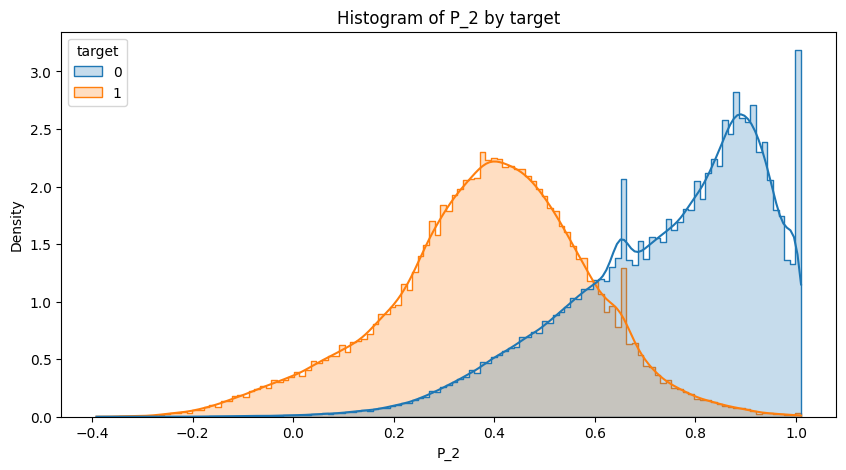

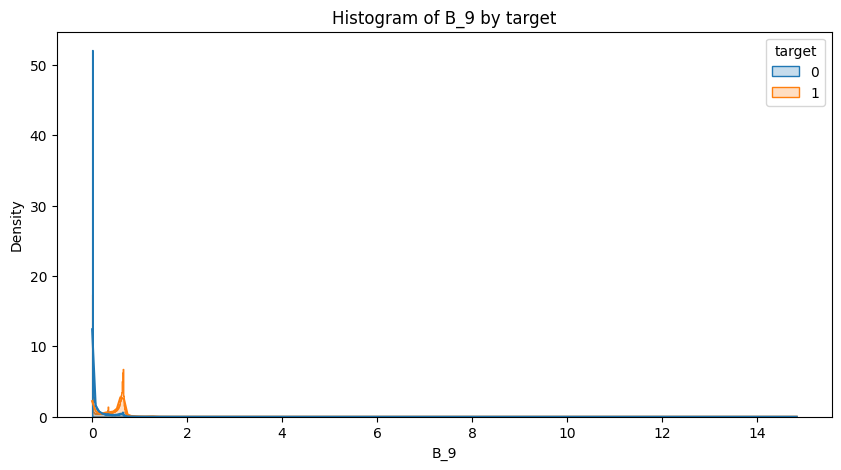

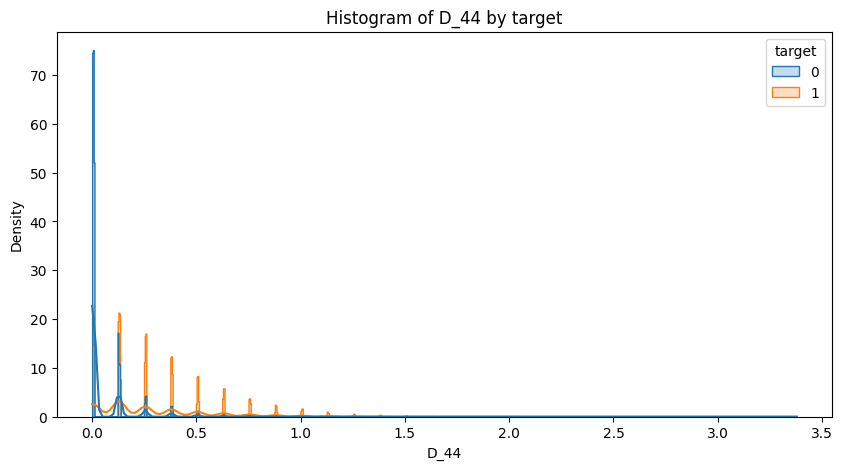

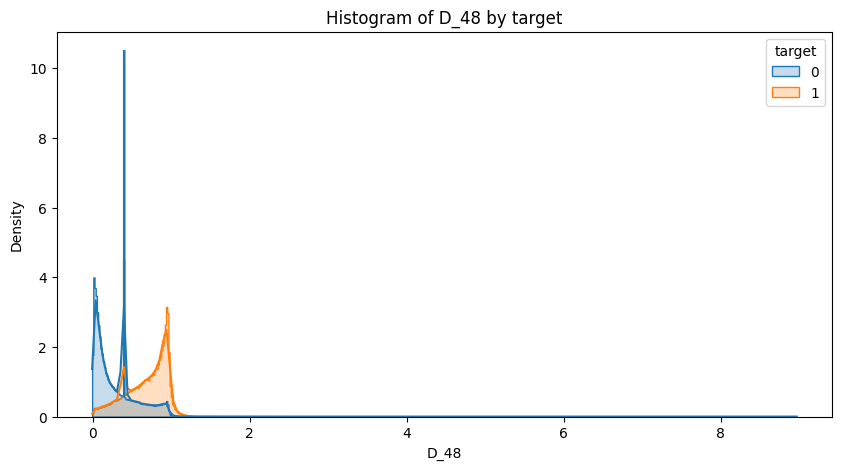

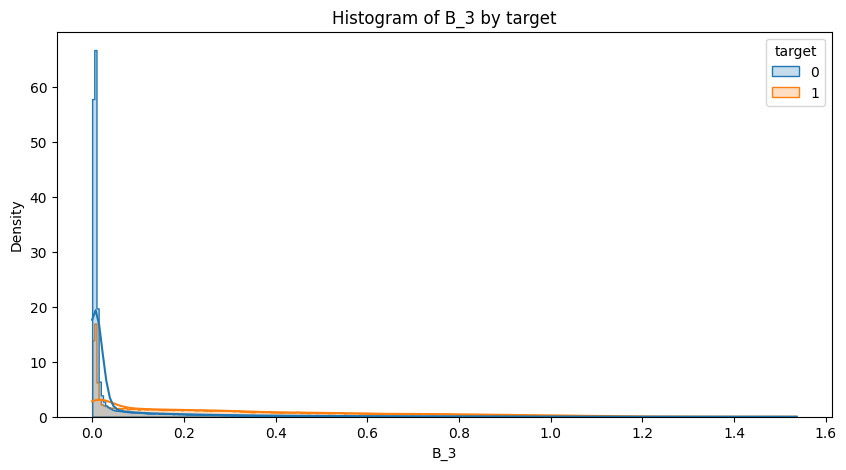

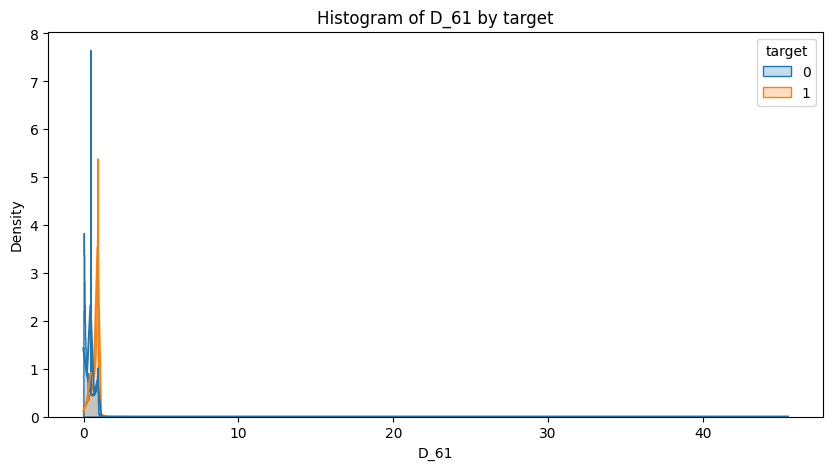

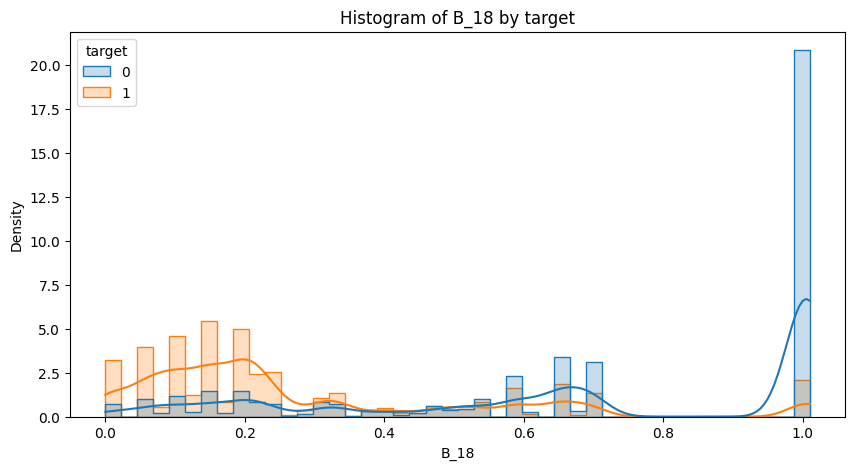

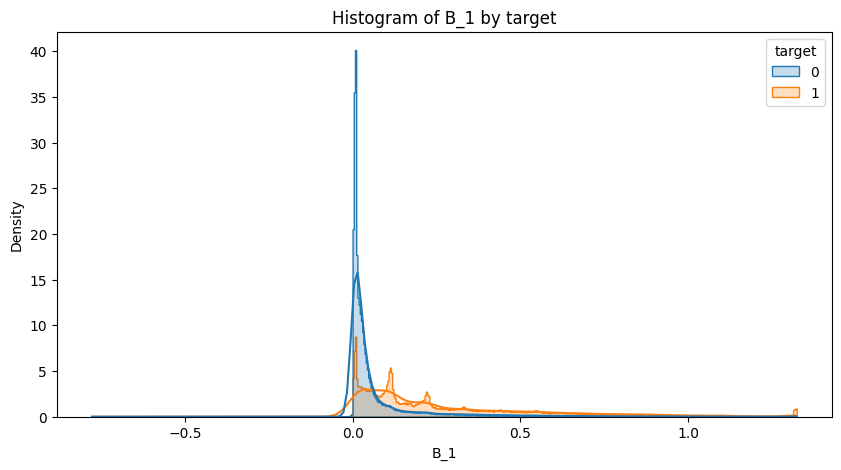

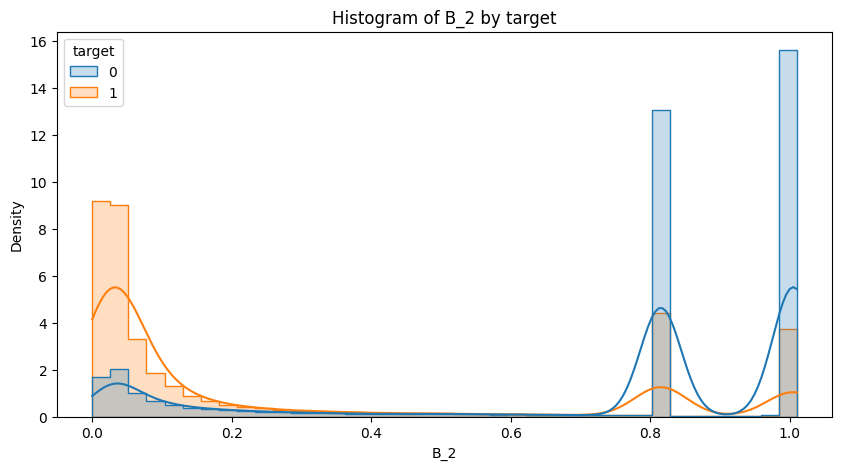

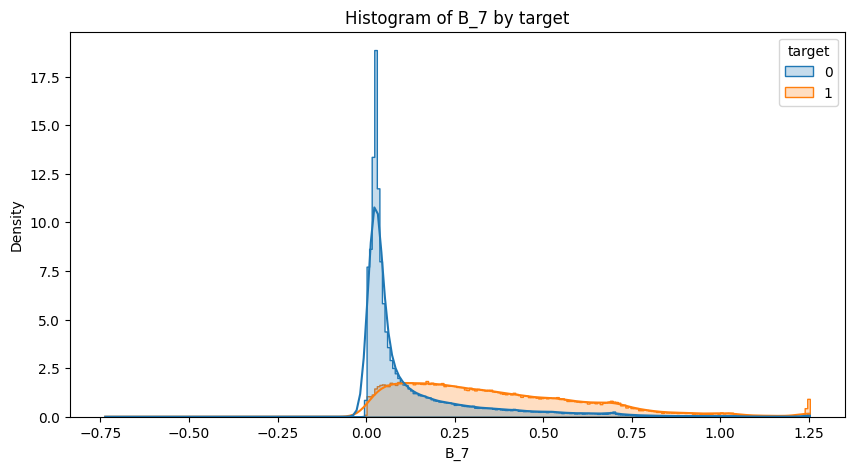

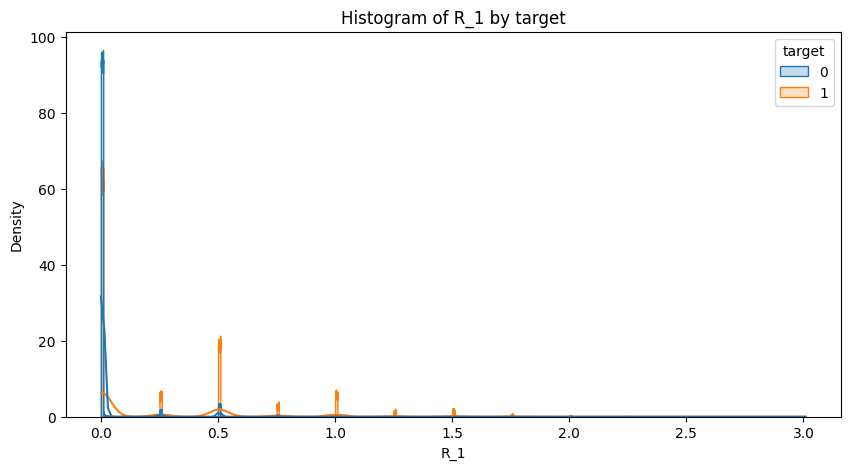

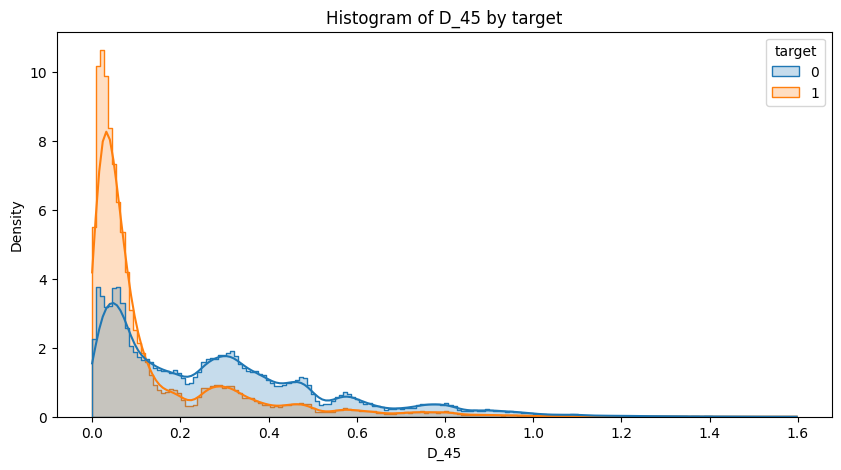

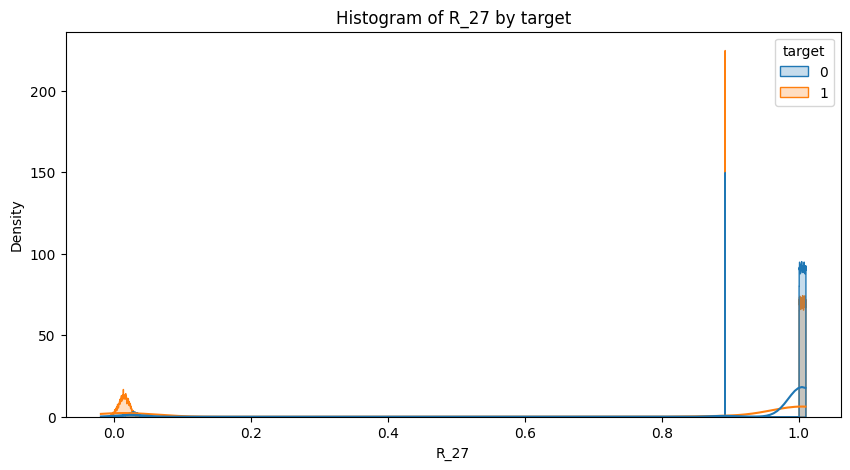

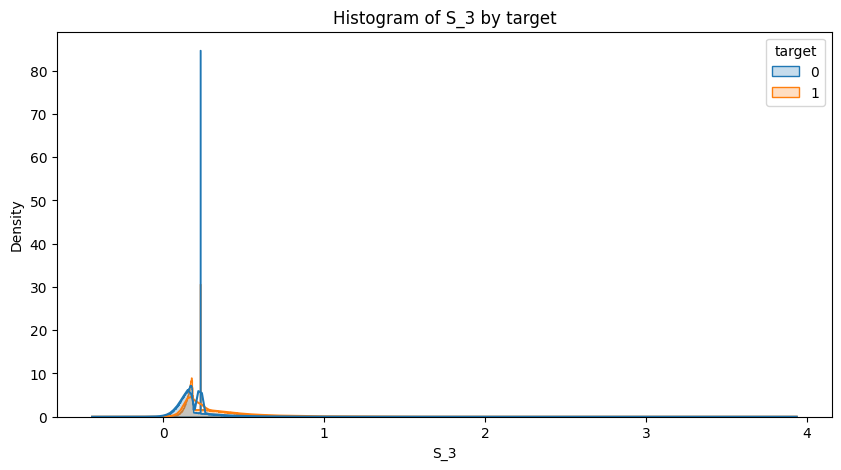

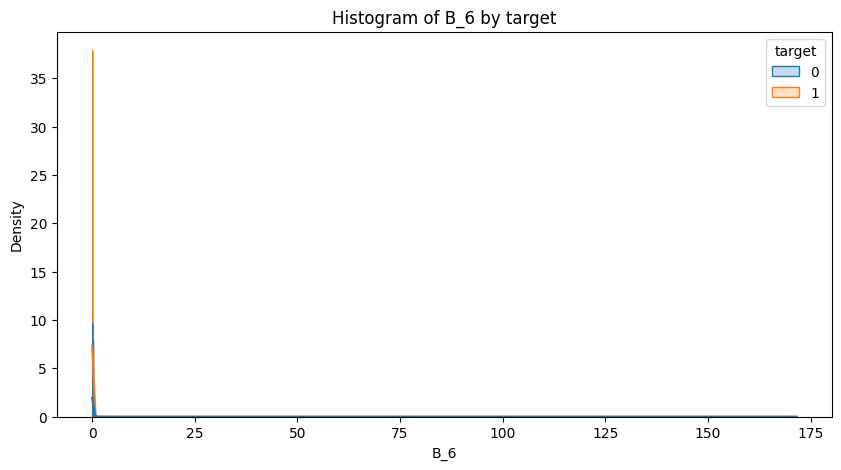

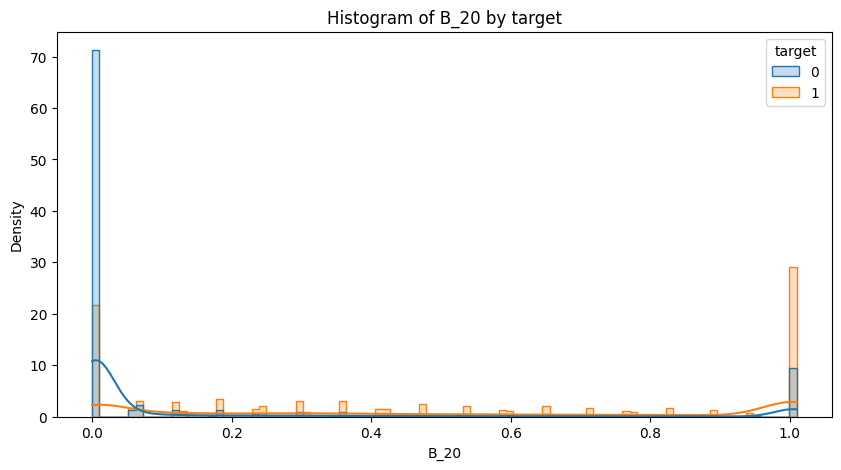

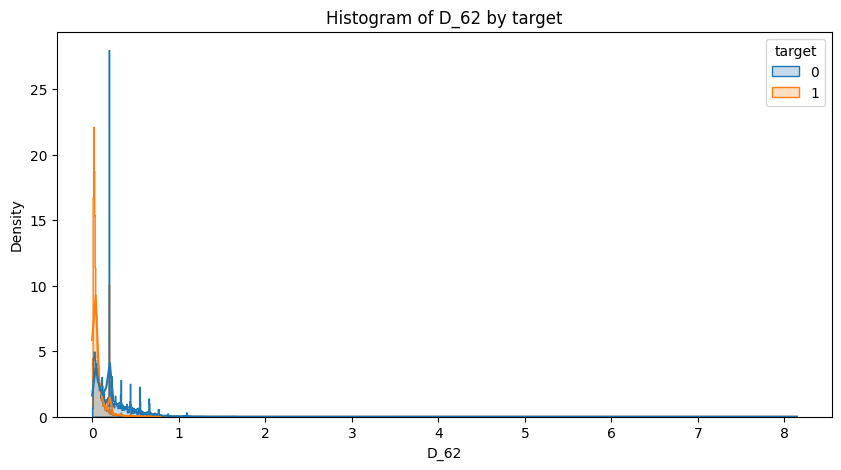

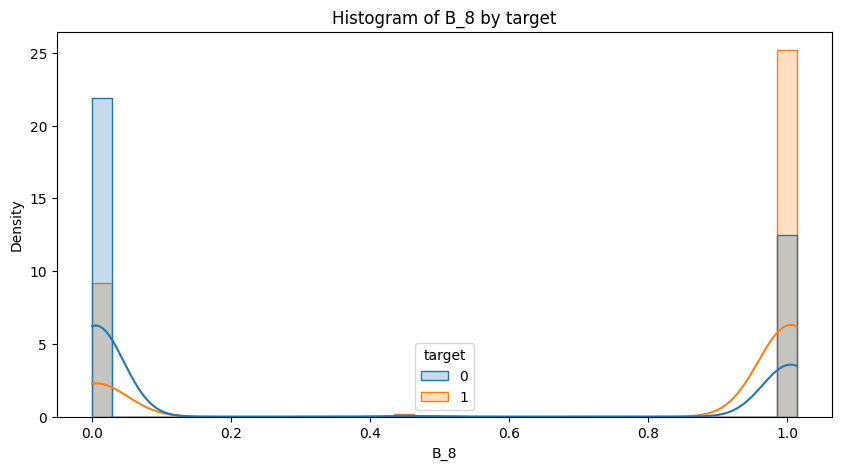

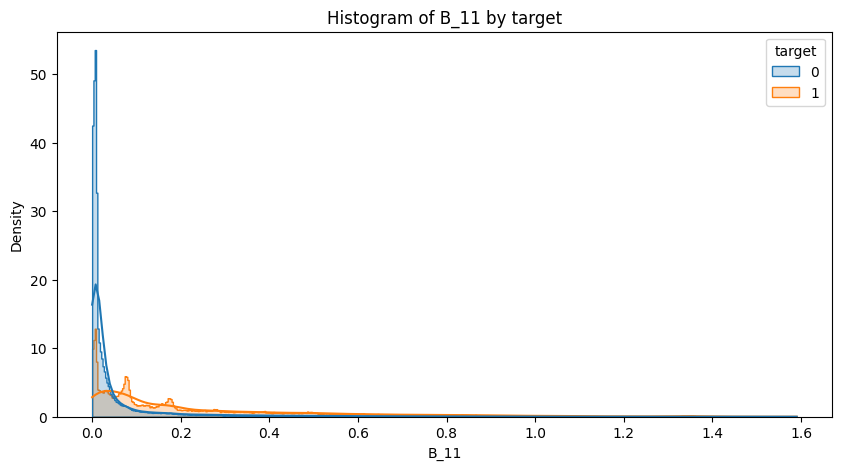

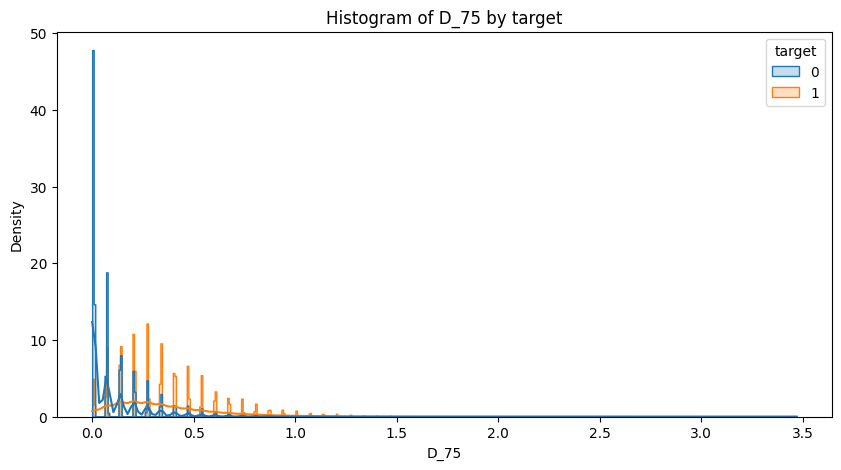

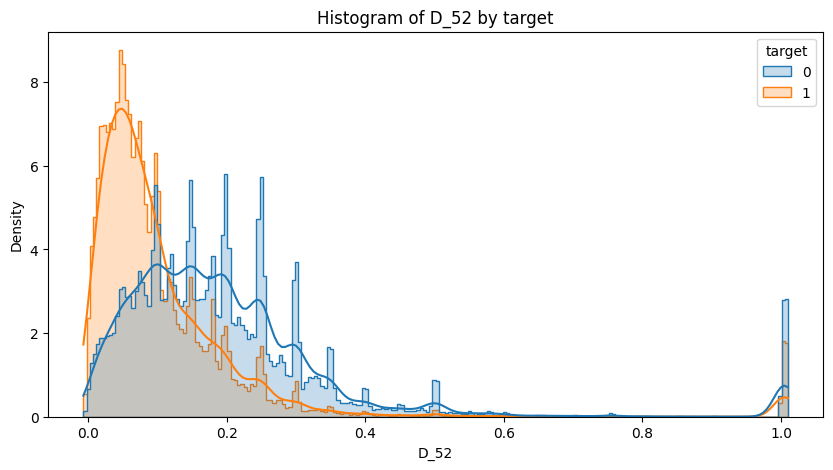

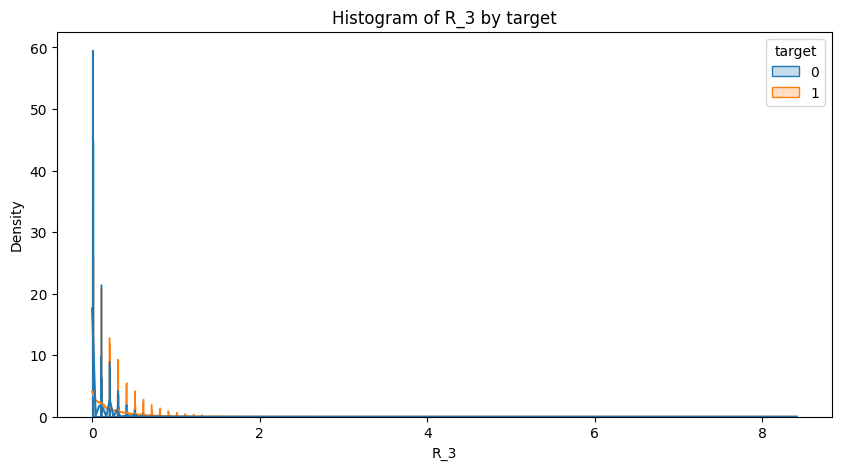

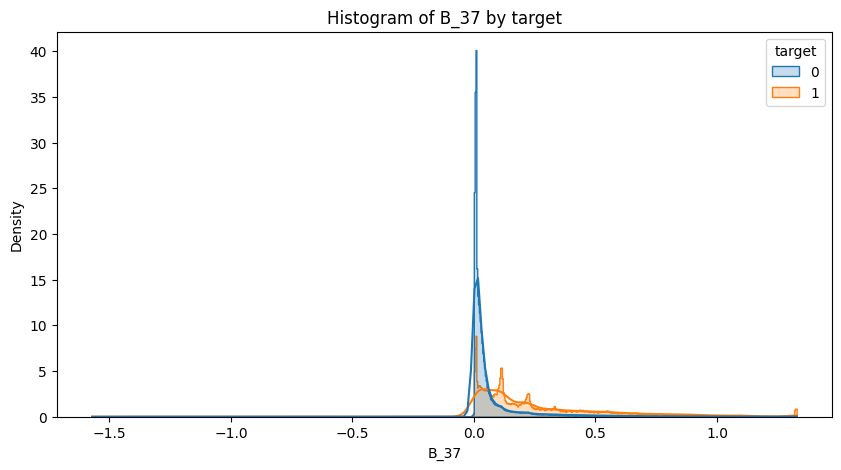

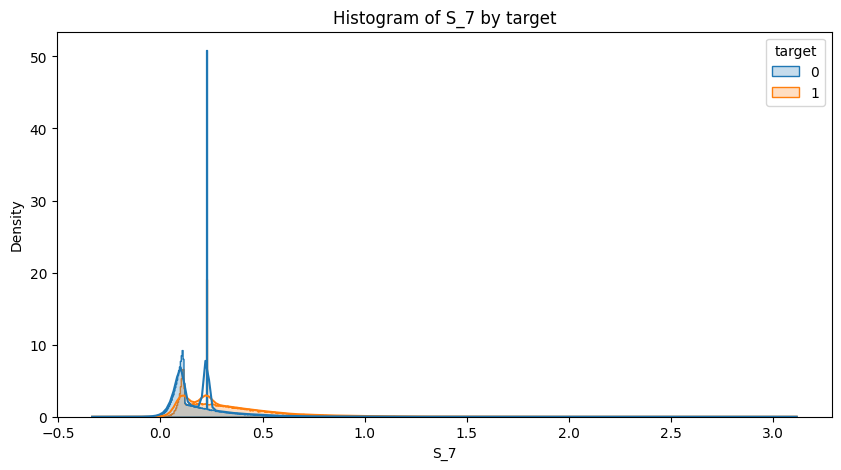

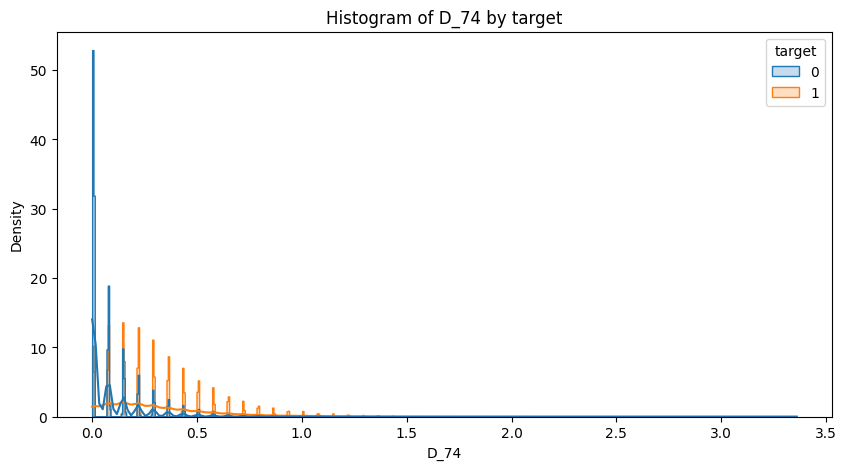

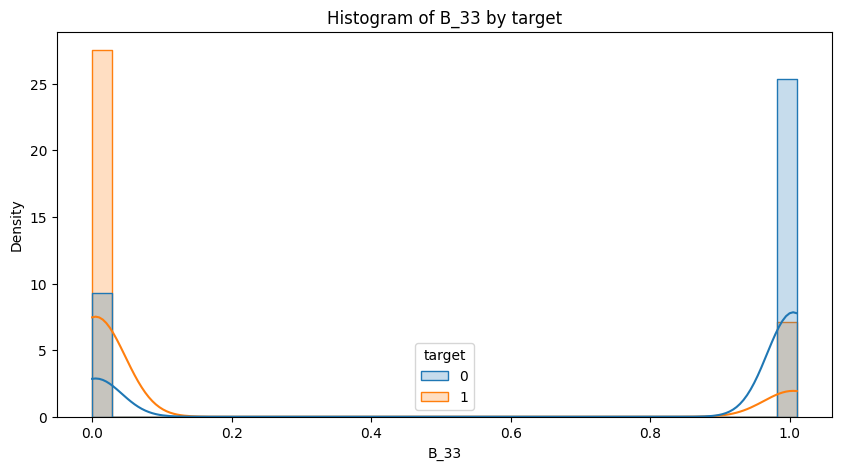

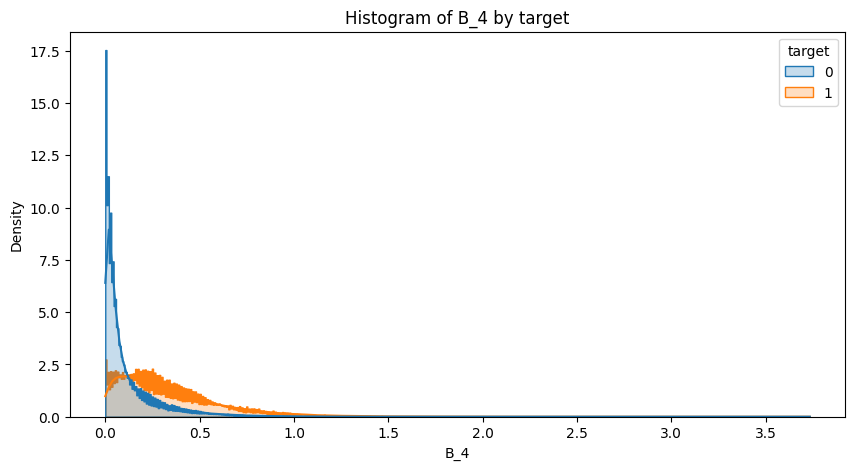

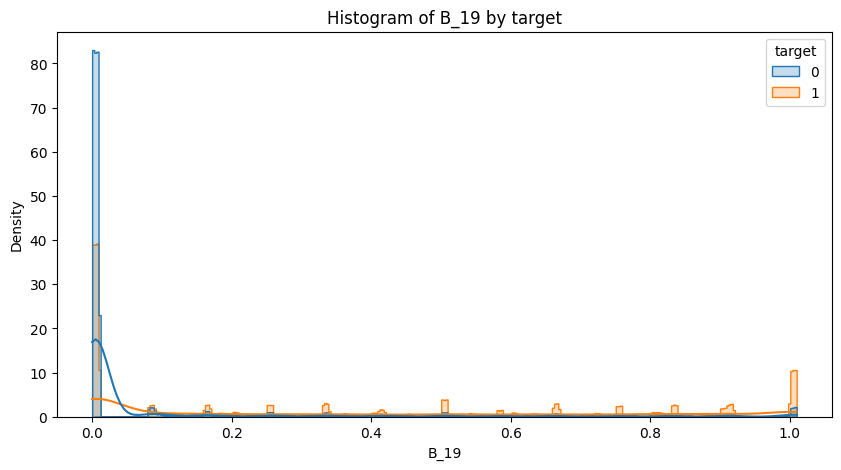

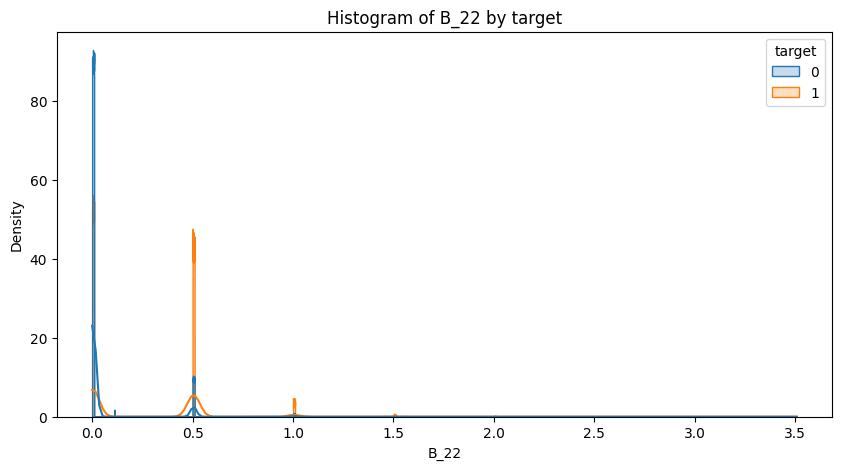

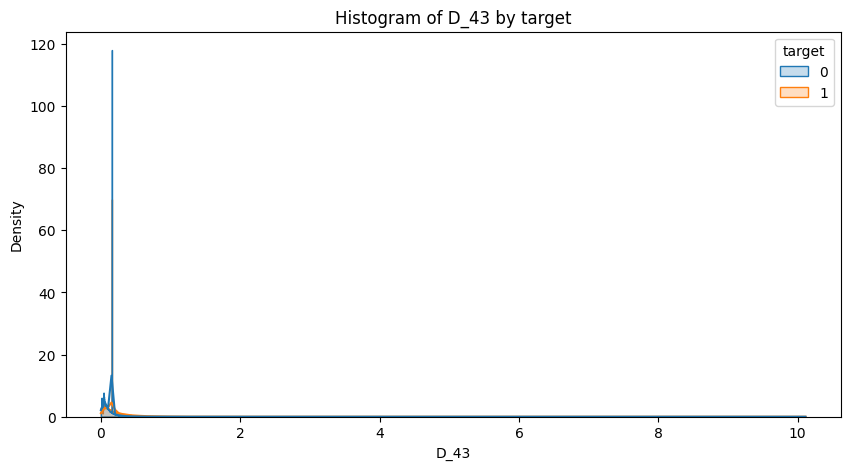

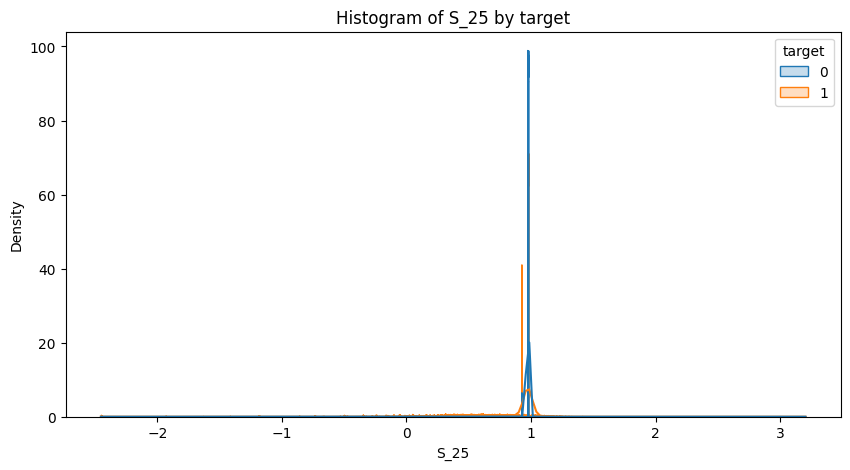

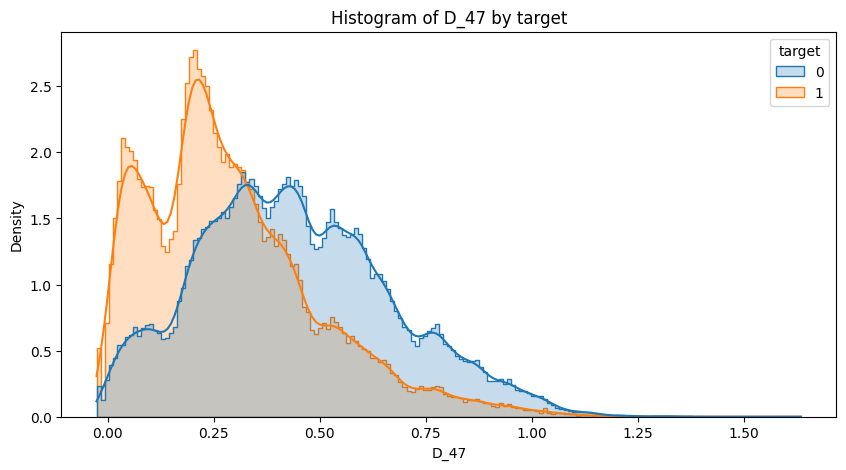

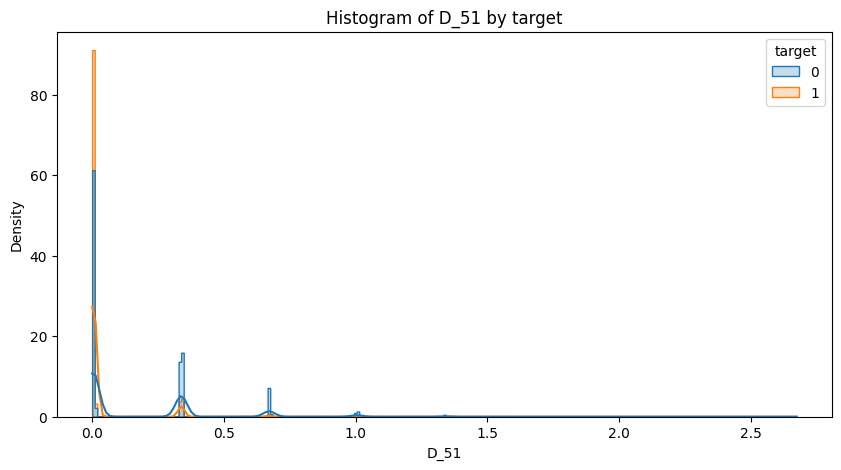

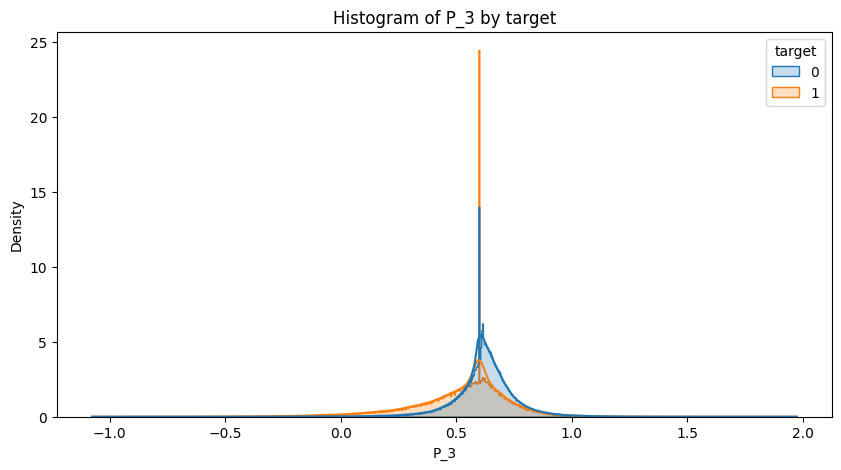

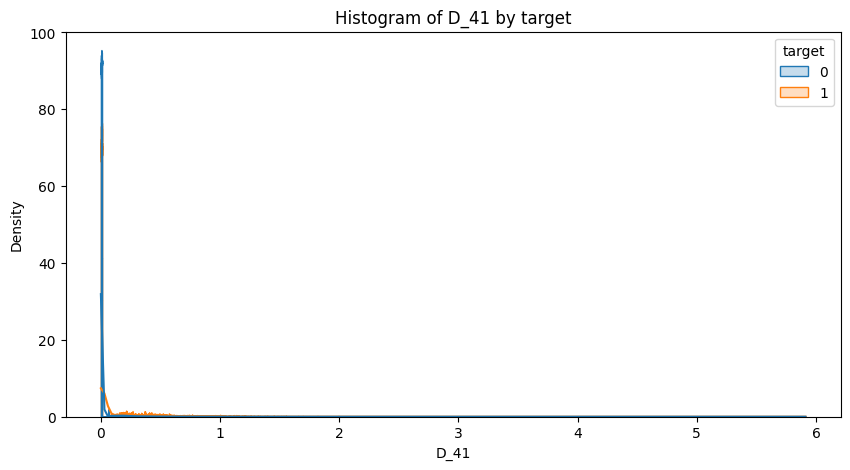

/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


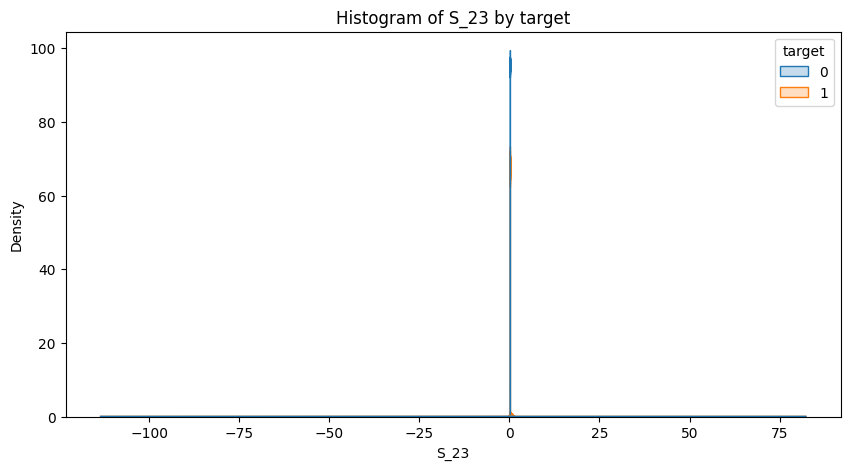

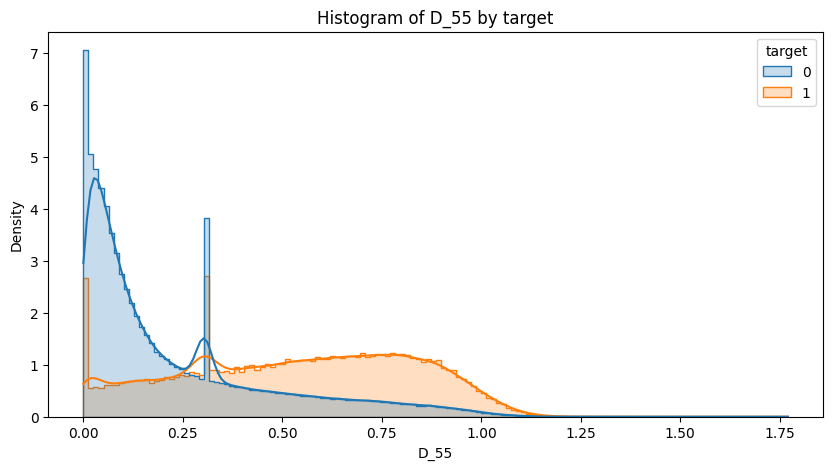

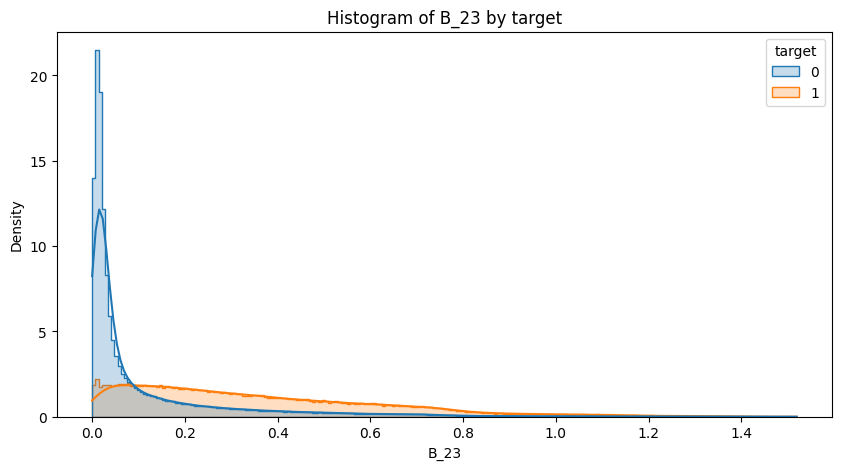

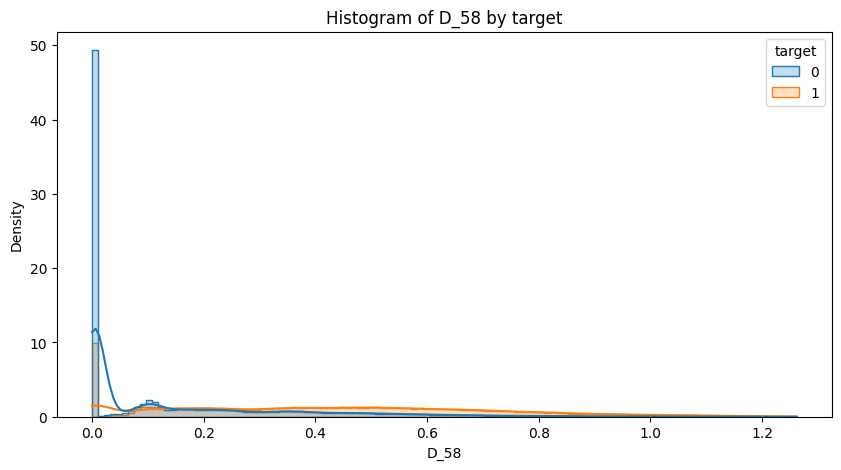

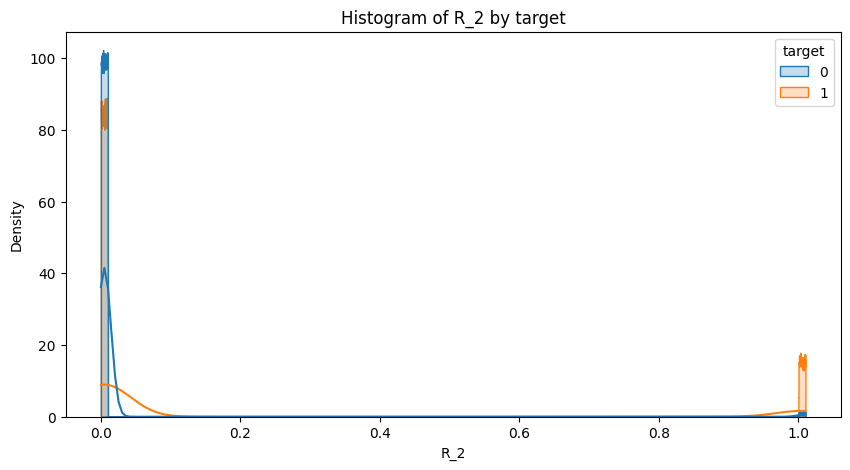

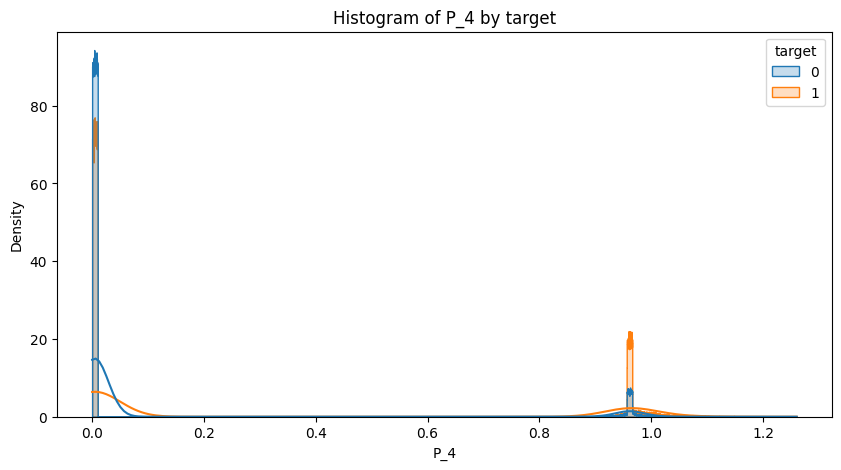

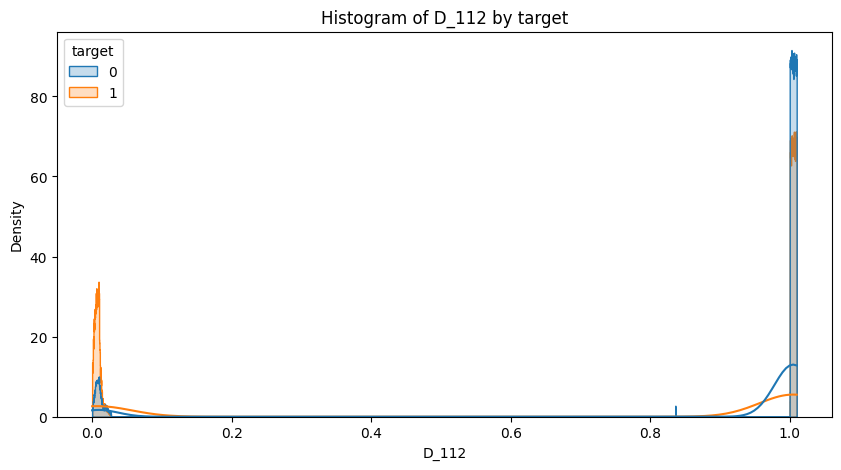

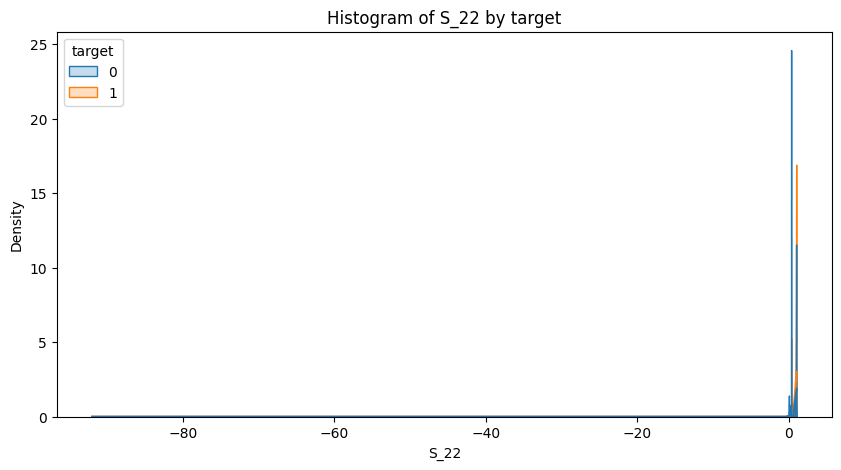

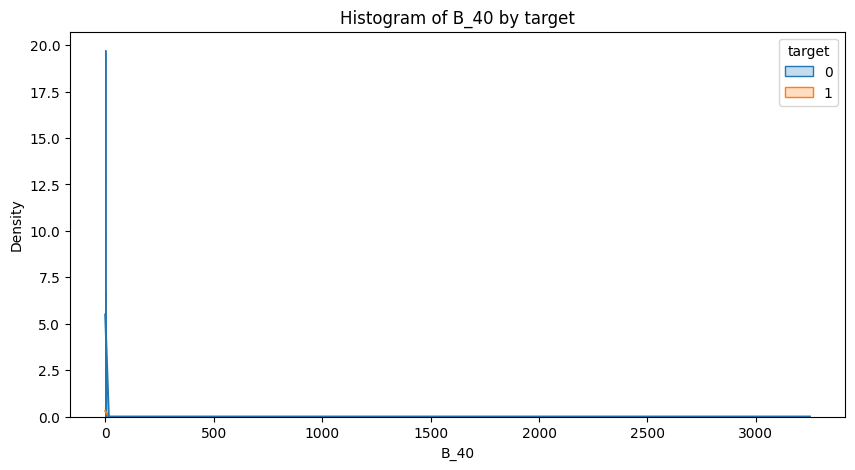

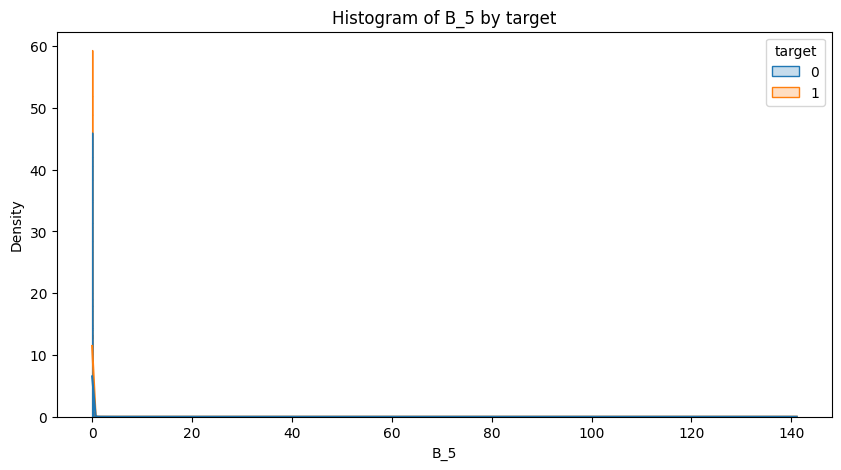

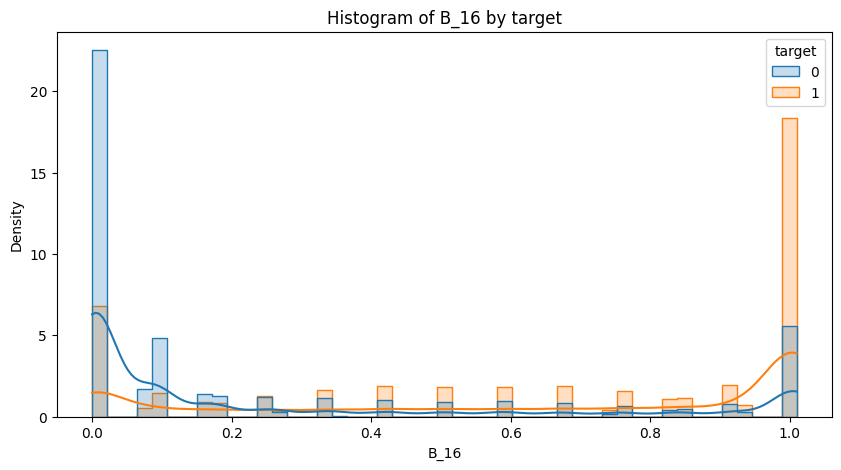

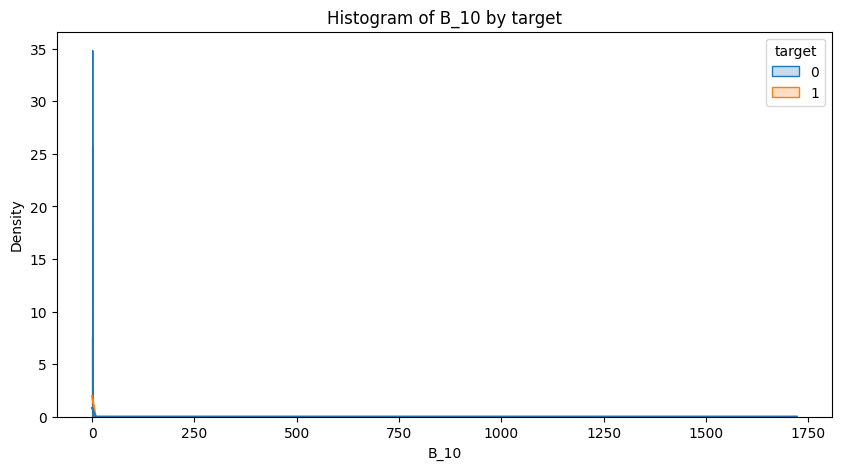

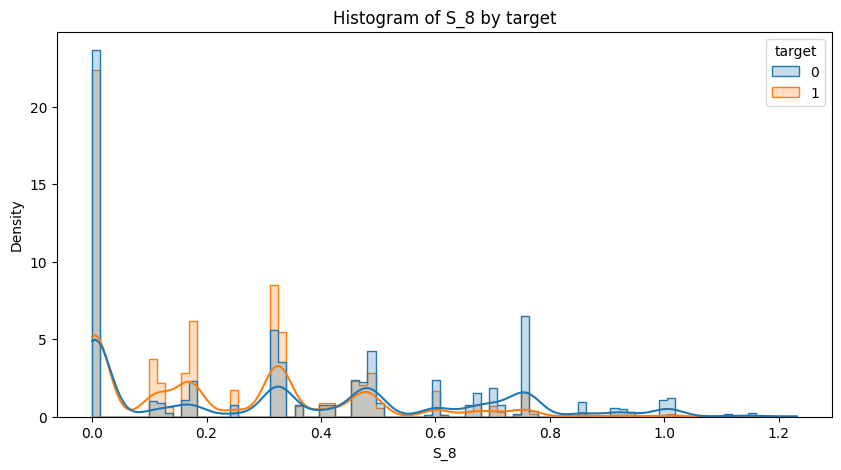

In [ ]:
numerical_cols = filtered_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = filtered_df.select_dtypes(include=['object', 'category']).columns.tolist()
target_col = 'target'  # replace with your actual target column name

# Remove target column from analysis lists if included
numerical_cols = [col for col in numerical_cols if col != target_col]
categorical_cols = [col for col in categorical_cols if col != target_col]

for col in numerical_cols:
    plt.figure(figsize=(10, 5))
    sns.histplot(data=df, x=col, hue=target_col, kde=True, element='step', stat='density', common_norm=False)
    plt.title(f'Histogram of {col} by {target_col}')
    plt.xlabel(col)
    plt.ylabel('Density')
    plt.show()

for col in categorical_cols:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x=col, hue=target_col)
    plt.title(f'Count of {col} grouped by {target_col}')
    plt.xticks(rotation=45)
    plt.ylabel('Count')
    plt.xlabel(col)
    plt.legend(title=target_col)
    plt.show()

**Data Balancing**

In [ ]:
smote = SMOTE(random_state=42)
X=filtered_df.drop(['target'],axis=1)
y=filtered_df['target']
X_balanced, y_balanced = smote.fit_resample(X, y)



**Model Creation**

In [ ]:
# 3. Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_balanced, y_balanced, test_size=0.2, stratify=y_balanced, random_state=42
)

In [ ]:
X_train.head()

,P_2,B_9,D_44,D_48,B_3,D_61,B_18,B_1,B_2,B_7,R_1,D_45,R_27,S_3,B_6,B_20,D_62,B_8,B_11,D_75,D_52,R_3,B_37,S_7,D_74,B_33,B_4,B_19,B_22,D_43,S_25,D_47,D_51,P_3,D_41,S_23,D_55,B_23,D_58,R_2,P_4,D_112,S_22,B_40,B_5,B_16,B_10,S_8
326410,0.609172,0.008918,0.131603,0.209304,0.031817,0.199074,0.645118,0.004470,0.814011,0.060701,0.000892,0.044767,1.006705,0.079666,0.041533,0.007618,0.036829,1.001508,0.004712,0.140684,0.085239,0.107258,0.008594,0.061920,0.152505,1.009884,0.068407,0.337324,0.007599,0.156570,0.976895,0.186448,0.009035,0.843376,0.004742,0.135020,0.428722,0.037985,0.106797,0.009187,0.003108,1.000124,0.874962,0.042696,0.011347,0.835834,0.077868,0.252404
339333,0.370492,0.630064,0.045854,0.568837,0.719323,0.565963,0.210910,0.630139,0.027799,0.527034,0.157088,0.057335,0.018655,0.257711,0.012467,0.954177,0.015915,1.006589,0.571686,0.179694,0.034306,0.033758,0.636794,0.236806,0.120136,0.006928,0.241524,0.980085,0.500636,0.146256,0.182153,0.028240,0.005557,0.488193,0.002861,0.437818,0.267390,0.447709,0.260902,0.002503,0.003358,1.004987,0.928742,0.333093,0.012435,1.005947,0.019241,0.008061
334102,0.467423,0.595923,0.254350,0.831090,0.011793,0.901931,0.650555,0.111175,0.815604,0.514890,0.006812,0.003141,0.946953,0.352318,0.116695,0.005587,0.020433,1.008872,0.079881,0.304073,0.028884,0.301831,0.112830,0.334549,0.330454,1.003383,0.202306,0.006289,0.005885,0.156902,0.975768,0.235001,0.003901,0.597548,0.004448,0.136376,0.133845,0.437182,0.234074,0.005109,0.963990,1.007146,0.964535,0.176985,0.010514,0.004641,0.026026,0.675571
249565,0.773171,0.137362,0.009817,0.006855,0.006957,0.152695,1.009846,0.053696,1.007027,0.057024,0.001940,0.005167,1.001402,0.111171,0.166549,0.001993,0.215596,1.006577,0.039526,0.007062,0.102030,0.209055,0.052540,0.094623,0.001297,1.003853,0.030665,0.005301,0.003920,0.015415,0.976093,0.414578,0.341289,0.661876,0.004697,0.136916,0.058522,0.043555,0.001533,0.008428,0.953194,1.003748,0.928725,0.050690,0.075460,0.004099,0.302475,0.916172
26850,0.726082,0.103793,0.000979,0.705789,0.056252,0.687878,0.241945,0.045311,0.213505,0.180607,0.005126,0.069513,1.009286,0.597410,0.025611,0.177740,0.013333,1.001843,0.026264,0.201731,0.062767,0.006520,0.042250,0.424536,0.150535,0.008507,0.213911,0.006296,0.008809,0.042256,0.972930,0.222689,0.005108,0.774991,0.009918,0.132410,0.625624,0.151489,0.152994,0.004583,0.004479,1.009489,0.961002,0.554643,0.023821,0.670840,0.060566,0.247505


In [ ]:
X_train.columns

Index(['P_2', 'B_9', 'D_44', 'D_48', 'B_3', 'D_61', 'B_18', 'B_1', 'B_2',
       'B_7', 'R_1', 'D_45', 'R_27', 'S_3', 'B_6', 'B_20', 'D_62', 'B_8',
       'B_11', 'D_75', 'D_52', 'R_3', 'B_37', 'S_7', 'D_74', 'B_33', 'B_4',
       'B_19', 'B_22', 'D_43', 'S_25', 'D_47', 'D_51', 'P_3', 'D_41', 'S_23',
       'D_55', 'B_23', 'D_58', 'R_2', 'P_4', 'D_112', 'S_22', 'B_40', 'B_5',
       'B_16', 'B_10', 'S_8'],
      dtype='object')

**Neural Network**

In [ ]:
model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')  # Binary classification
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
early_stop = EarlyStopping(monitor='accuracy', patience=3, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=1024,  # Good for large datasets
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.8248 - auc: 0.8963 - loss: 0.3999 - val_accuracy: 0.8627 - val_auc: 0.9323 - val_loss: 0.3249
Epoch 2/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8616 - auc: 0.9303 - loss: 0.3305 - val_accuracy: 0.8647 - val_auc: 0.9344 - val_loss: 0.3206
Epoch 3/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.8653 - auc: 0.9329 - loss: 0.3239 - val_accuracy: 0.8664 - val_auc: 0.9354 - val_loss: 0.3169
Epoch 4/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8669 - auc: 0.9343 - loss: 0.3200 - val_accuracy: 0.8678 - val_auc: 0.9363 - val_loss: 0.3140
Epoch 5/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8670 - auc: 0.9352 - loss: 0.3176 - val_accuracy: 0.8688 - val_auc: 0.9372 - val_loss: 0.3120
Epoch 6/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8693 - auc: 0.9361 - loss: 0.3141 - val_accuracy: 0.8691 - val_auc: 0.9378 - val_loss: 0.3102
Epoch 7/20
303/303 ━━━━━━━━━━━━━━━

In [ ]:
results= model.evaluate(X_test, y_test, verbose=0)

print(f"Test Accuracy: {results[1]:.4f}")

Test Accuracy: 0.8748


In [ ]:
feature_names = X_train.columns.tolist()
class_names = ['Class 0', 'Class 1']  # adjust if your target has different labels




**Model Explanation**

In [ ]:
# Create the LIME explainer
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train[:100].values,
    feature_names=feature_names,
    class_names=class_names,
    mode='classification'
)



In [ ]:
# Pick an index to explain
i = 0  # explain the first test sample

# Create explanation for instance
lime_exp = lime_explainer.explain_instance(
    data_row=X_test.iloc[i].values,
    predict_fn=lambda x: np.hstack((1 - model.predict(x), model.predict(x))),
    num_features=10
)

# Show it inline (if using Jupyter) or save to HTML
lime_exp.show_in_notebook(show_table=True)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


/usr/local/lib/python3.11/dist-packages/shap/explainers/_deep/deep_tf.py:94: UserWarning: Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(100, 48))']
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(200, 48))']
  warnings.warn(msg)


<Figure size 640x480 with 0 Axes>

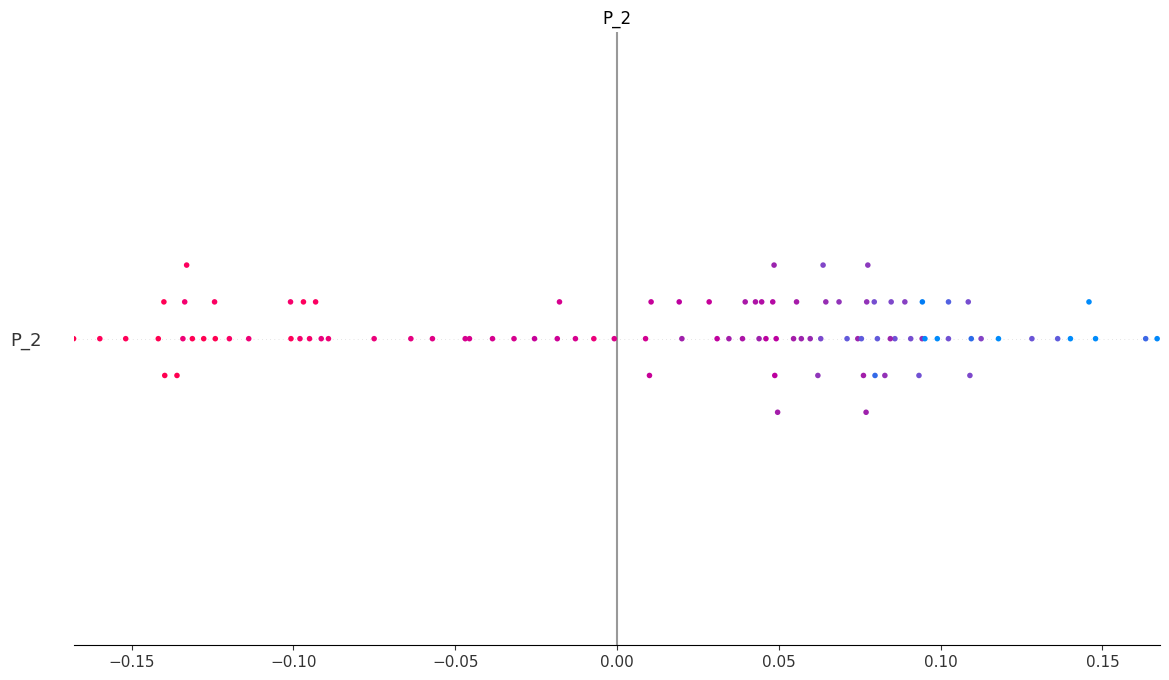

In [ ]:
background = X_train.iloc[np.random.choice(X_train.shape[0], 100, replace=False)]
explainer = shap.DeepExplainer(model, background)

# Choose a subset of test data to explain
shap_values = explainer.shap_values(X_test.iloc[:100].values)  # explain top 100 samples

# Plot summary
shap.summary_plot(shap_values, X_test.iloc[:100], feature_names=X.columns)

**Ensemble Model**

In [ ]:
lgb_model = lgb.LGBMClassifier(random_state=42, n_estimators=100)
lgb_model.fit(X_train, y_train)
lgb_preds = lgb_model.predict_proba(X_test)[:, 1]
xgb_model = xgb.XGBClassifier(random_state=42, n_estimators=100, use_label_encoder=False, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict_proba(X_test)[:, 1]
best_score = 0
best_weight = 0.5

for w in np.linspace(0, 1, 21):
    blended = w * lgb_preds + (1 - w) * xgb_preds
    score = roc_auc_score(y_test, blended)
    if score > best_score:
        best_score = score
        best_weight = w

print(f"Best Weight: LightGBM = {best_weight}, XGBoost = {1 - best_weight}, AUC = {best_score:.5f}")

[LightGBM] [Info] Number of positive: 193580, number of negative: 193580
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.388072 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 12240
[LightGBM] [Info] Number of data points in the train set: 387160, number of used features: 48
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [23:46:12] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Best Weight: LightGBM = 0.2, XGBoost = 0.8, AUC = 0.97236


In [ ]:
ensemble_preds = best_weight*lgb_model.predict_proba(X_test)[:, 1]+(1-best_weight)*xgb_model.predict_proba(X_test)[:, 1]
binary_preds = (ensemble_preds >= 0.5).astype(int)
accuracy = accuracy_score(y_test, binary_preds)
print(f"Ensemble Model Accuracy: {accuracy:.4f}")

Ensemble Model Accuracy: 0.9060


In [ ]:
import joblib
joblib.dump(lgb_model, 'lgb_model.pkl')
joblib.dump(xgb_model, 'xgb_model.pkl')

['xgb_model.pkl']

**Model Explanation**

LightGBM SHAP Summary:


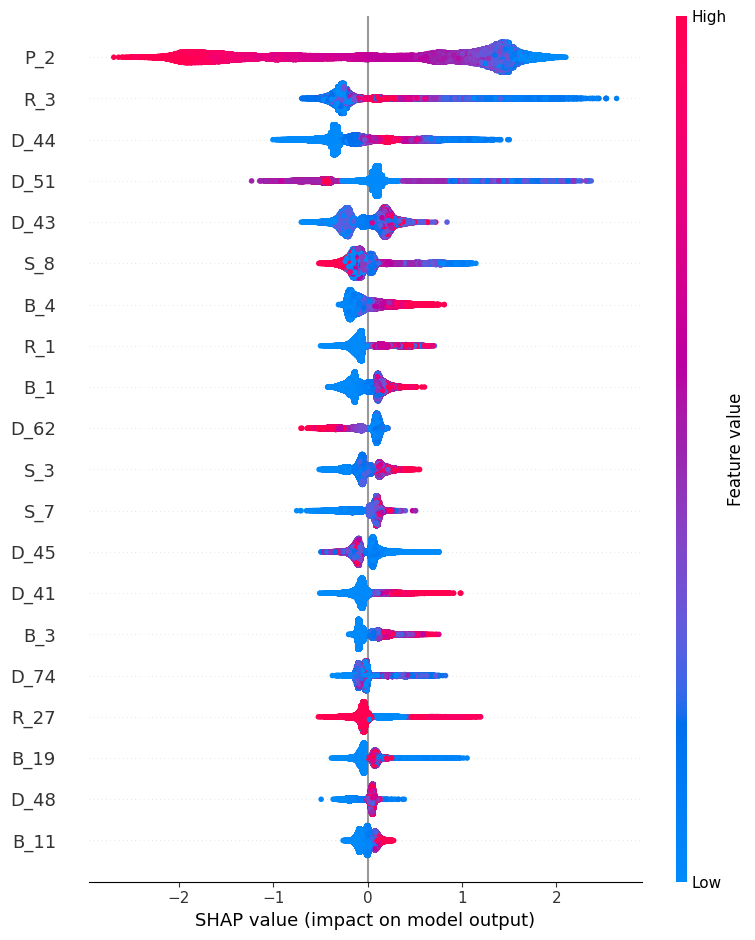

XGBoost SHAP Summary:


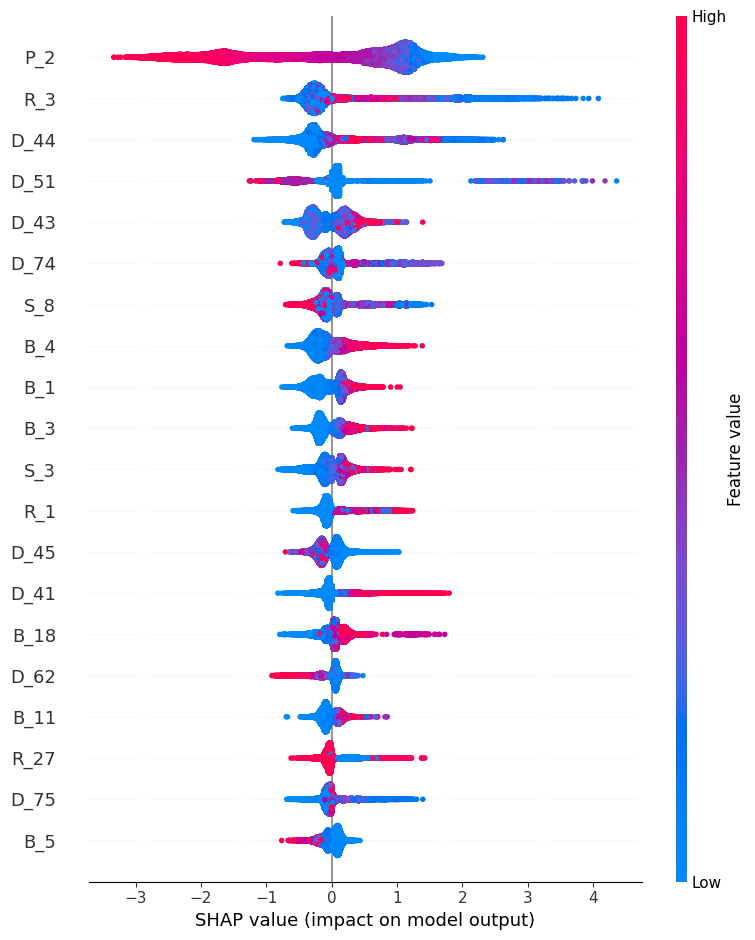

In [ ]:
explainer_lgb = shap.Explainer(lgb_model)
shap_values_lgb = explainer_lgb(X_test)

# Explain XGBoost with SHAP
explainer_xgb = shap.Explainer(xgb_model)
shap_values_xgb = explainer_xgb(X_test)

# SHAP summary plots
print("LightGBM SHAP Summary:")
shap.summary_plot(shap_values_lgb, X_test)

print("XGBoost SHAP Summary:")
shap.summary_plot(shap_values_xgb, X_test)

# Optional: Compare average absolute SHAP values
avg_abs_shap_lgb = np.abs(shap_values_lgb.values).mean(axis=0)
avg_abs_shap_xgb = np.abs(shap_values_xgb.values).mean(axis=0)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'LGB Importance': avg_abs_shap_lgb,
    'XGB Importance': avg_abs_shap_xgb
}).sort_values(by='XGB Importance', ascending=False)

**RandomForestClassifier**

In [ ]:
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:

y_pred_rf = rf_model.predict(X_test)

accuracy_lgb = accuracy_score(y_test, y_pred_rf)

print(f"Random Forest Accuracy: {accuracy_lgb:.4f}")

Random Forest Accuracy: 0.9082


**Model Explanation**

In [ ]:
lime_exp_lgb = lime_explainer.explain_instance(
    data_row=X_test.iloc[0].values,
    predict_fn=lgb_model.predict_proba,
    num_features=10
)
lime_exp_lgb.show_in_notebook(show_table=True)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
